# Lagunazo mine waste - ICP geochemistry of CRMs

## 1 · Configuration

In [1]:
import re
import math
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.backends.backend_pdf import PdfPages
from openpyxl import load_workbook
from scipy import stats as sps
from pyproj import Transformer

warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 120)

# paths
PROJECT_DIR = Path.cwd()                 # run from the folder that holds 'data/'
DATA_DIR = PROJECT_DIR / "data"
OUT_DIR = PROJECT_DIR / "outputs" / "ICP_CRM"
FIG_DIR = OUT_DIR / "figures"
MAP_DIR = FIG_DIR / "maps"
TAB_DIR = OUT_DIR / "tables"
for _d in (OUT_DIR, FIG_DIR, MAP_DIR, TAB_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def find_input(name):
    """Return the first existing path for `name` in data/ or the project folder."""
    for p in (DATA_DIR / name, PROJECT_DIR / name):
        if p.exists():
            return p
    return None


ICP_FILE = find_input("ICP-DATA_2026.xlsx")
if ICP_FILE is None:
    raise FileNotFoundError("ICP-DATA_2026.xlsx not found in data/ or the project folder")

# Optional inputs from the pXRF workflow (Final_XRF_samples_mapping_r3.ipynb)
PXRF_COORDS_FILE = find_input("Lagunazo_UTM.csv")                 # columns ID, X, Y (UTM 29N)
PXRF_WASTE_FILE = find_input("XRF_2024_samples_waste_type.csv")   # columns Sample, Type
PXRF_DATA_FILE = find_input("XRF_Lagunazo_complete_r2.csv")       # readings, one row per shot

# coordinate reference systems
CRS_GEOGRAPHIC = "EPSG:4326"  
CRS_PROJECTED = "EPSG:32629"   # WGS 84 / UTM zone 29N
# ETRS89 / UTM 29N (EPSG:25829), the Spanish official frame, differs from WGS 84 by well under
# a metre here - far below handheld GNSS error (typically 3-5 m).

# Extent of the pXRF sample locations printed by Final_XRF_samples_mapping_r3 (section 8).
# Used only as a plausibility frame when Lagunazo_UTM.csv is not available.
PXRF_EXTENT_REFERENCE = dict(xmin=661445.3, xmax=661929.5, ymin=4165390.0, ymax=4165819.4)

# location-ID corrections
# Format-only normalisations (letter case, zero padding, separators) are always applied and
# reported. The field list uses the prefix 'LG' where the laboratory submission uses 'LA' for
# the same 2025 numbers; this is treated as a naming convention [CONFIRM].
# The three corrections below are INFERENCES. They are applied only when
# APPLY_PROBABLE_ID_CORRECTIONS is True, and every map that uses them says so.
APPLY_PROBABLE_ID_CORRECTIONS = True
LOCATION_ID_CORRECTIONS = {
    # row 'No.' in the Locations sheet: (ID as recorded, corrected ID, basis)
    13: ("LG-35-31", "LA-25-31",
         "year typed '35': no 2035 series exists, number 31 is otherwise absent from the list, "
         "and the point lies with its neighbours 03, 33 and 29 in the north-central part"),
    23: ("LH-25-06", "LA-25-06",
         "prefix typed 'LH' (H is next to G on the keyboard); number 06 is otherwise absent"),
    29: ("LG-25-34", "LA-25-24",
         "ID 34 is recorded twice (rows 29 and 44) while 24 is absent; row 29 sits between "
         "25 (row 28) and 23 (row 30) both in the list order and on the ground"),
}

# Waste type for samples not covered by XRF_2024_samples_waste_type.csv, from the field log.
# Example: {"LA-25-19": "tailings"}  
WASTE_TYPE_OVERRIDES = {}

# Spearman rho of the pXRF Bi-Sb co-kriging pair as reported in the thesis
PXRF_SB_BI_RHO = 0.75

# figure output
SAVE_FORMATS = ("pdf", "svg")      # vector, LaTeX-ready
USE_BASEMAP = False                # True: Esri World Imagery under the maps (needs contextily + internet)

def _rel(p):
    return p.relative_to(PROJECT_DIR) if (p is not None and p.is_relative_to(PROJECT_DIR)) else p


print(f"ICP workbook          : {_rel(ICP_FILE)}")
print(f"pXRF coordinates      : {_rel(PXRF_COORDS_FILE) or 'not found - LA-24 samples will be listed, not mapped'}")
print(f"pXRF waste-type table : {_rel(PXRF_WASTE_FILE) or 'not found'}")
print(f"pXRF readings         : {_rel(PXRF_DATA_FILE) or 'not found - section 10 will be skipped'}")
print(f"Outputs               : {_rel(OUT_DIR)}")

ICP workbook          : ICP-DATA_2026.xlsx
pXRF coordinates      : data\Lagunazo_UTM.csv
pXRF waste-type table : data\XRF_2024_samples_waste_type.csv
pXRF readings         : data\XRF_Lagunazo_complete_r2.csv
Outputs               : outputs\ICP_CRM


## 2 · Reference lists: EU critical and strategic raw materials, background, digestion

**Regulation (EU) 2024/1252** (Critical Raw Materials Act) lists 34 critical raw materials in Annex II and, of these, 17 strategic raw materials in Annex I. The Act names rare earths only as two groups; the element split used here is the one of the EU 2023 criticality assessment: light REE = La, Ce, Pr, Nd, Sm; heavy REE = Eu, Gd, Tb, Dy, Ho, Er, Tm, Yb, Lu **and Y**; scandium is assessed separately. The strategic entry "rare earth elements for magnets" covers Nd, Pr, Tb, Dy, Gd, Sm and Ce.

Two points matter for this thesis. **Indium is not on either list** (it was on the 2020 list, COM(2020) 474, and was dropped in 2023); it is carried here only as a thesis target element and labelled as such. **Copper and nickel (battery grade)** are on the critical list because every strategic raw material is also critical, even though neither meets the criticality thresholds on its own.

**What aqua regia measures.** Aqua regia dissolves sulphides, sulphosalts, carbonates, Fe-Mn oxyhydroxides and most sulphates (anglesite only in part, barite not at all), but not quartz, feldspar, most micas, zircon, rutile, columbite–tantalite, chromite or cassiterite, and ilmenite only slowly. Each element is therefore given a digestion class, and the enrichment ratio to crustal background is computed only where aqua regia can be expected to approach a total:

| Class | Meaning | Elements (AQ251) |
|---|---|---|
| **A** near-total | hosts are acid-soluble in this sulphide–sulphate–oxide matrix | As, Bi, Co, Cu, Mn, Ni, Sb (Sb oxides may be incompletely extracted) and In |
| **B** partial | a large part sits in silicates or resistate minerals; values are the aqua-regia-extractable fraction, not the content | Al, B, Ba, Be, Ce, Ga, Ge, Hf, La, Li, Mg, Nb, P, Sc, Sr, Ta, Ti, V, W, Y |
| **C** screening | aqua regia dissolves Pd and Pt, but a 2–10 ppb detection limit on a small aliquot is a screen, not an assay; fire assay is the reference method | Pd, Pt |
| **F** total | lithium-borate fusion dissolves the whole sample | SiO₂, TiO₂, Al₂O₃, MgO, MnO, P₂O₅, Ba (LF725) |

Germanium carries an extra caveat: GeCl₄ is volatile, so hot HCl-bearing digestions can lose Ge. Background values are the upper continental crust of Rudnick & Gao (2014), the same reference as the pXRF notebook.

In [2]:
# Annex II (critical) entries, their Annex I (strategic) counterpart, and what the two packages measured.
CRMA_ENTRIES = [
    # (Annex II entry, Annex I strategic entry or "", [(method, analyte), ...], note)
    ("Antimony", "", [("AQ251", "Sb")], ""),
    ("Arsenic", "", [("AQ251", "As")], "also the governing health constraint on this material"),
    ("Bauxite/alumina/aluminium", "Bauxite/alumina/aluminium", [("AQ251", "Al"), ("LF725", "Al2O3")],
     "Al is a proxy only - the waste is not bauxite"),
    ("Baryte", "", [("AQ251", "Ba"), ("LF725", "Ba")], "barite is insoluble in aqua regia; LF725 Ba is the total"),
    ("Beryllium", "", [("AQ251", "Be")], ""),
    ("Bismuth", "Bismuth", [("AQ251", "Bi")], ""),
    ("Boron", "Boron - metallurgy grade", [("AQ251", "B")], ""),
    ("Cobalt", "Cobalt", [("AQ251", "Co")], ""),
    ("Coking coal", "", [], "not an element determination"),
    ("Copper", "Copper", [("AQ251", "Cu"), ("LF725", "Cu")], ""),
    ("Feldspar", "", [], "mineral commodity - needs XRD"),
    ("Fluorspar", "", [], "F not in either package"),
    ("Gallium", "Gallium", [("AQ251", "Ga")], ""),
    ("Germanium", "Germanium", [("AQ251", "Ge")], ""),
    ("Hafnium", "", [("AQ251", "Hf")], ""),
    ("Helium", "", [], "gas"),
    ("Heavy rare earth elements", "Rare earth elements for magnets (Gd, Tb, Dy)", [("AQ251", "Y")],
     "only Y of the ten HREE is in the package; Gd, Tb, Dy not analysed"),
    ("Light rare earth elements", "Rare earth elements for magnets (Nd, Pr, Sm, Ce)", [("AQ251", "La"), ("AQ251", "Ce")],
     "Nd, Pr, Sm not analysed; Ce is the only magnet REE measured"),
    ("Lithium", "Lithium - battery grade", [("AQ251", "Li")], ""),
    ("Magnesium", "Magnesium metal", [("AQ251", "Mg"), ("LF725", "MgO")], ""),
    ("Manganese", "Manganese - battery grade", [("AQ251", "Mn"), ("LF725", "MnO")], ""),
    ("Natural graphite", "Natural graphite - battery grade", [], "C not analysed"),
    ("Nickel - battery grade", "Nickel - battery grade", [("AQ251", "Ni")], ""),
    ("Niobium", "", [("AQ251", "Nb")], ""),
    ("Phosphate rock", "", [("AQ251", "P"), ("LF725", "P2O5")], "P as proxy"),
    ("Phosphorus", "", [("AQ251", "P"), ("LF725", "P2O5")], ""),
    ("Platinum group metals", "Platinum group metals", [("AQ251", "Pd"), ("AQ251", "Pt")],
     "Rh, Ru, Ir, Os not analysed"),
    ("Scandium", "", [("AQ251", "Sc")], ""),
    ("Silicon metal", "Silicon metal", [("LF725", "SiO2")], "SiO2 of the waste, not a feedstock specification"),
    ("Strontium", "", [("AQ251", "Sr")], ""),
    ("Tantalum", "", [("AQ251", "Ta")], ""),
    ("Titanium metal", "Titanium metal", [("AQ251", "Ti"), ("LF725", "TiO2")], ""),
    ("Tungsten", "Tungsten", [("AQ251", "W")], ""),
    ("Vanadium", "", [("AQ251", "V")], ""),
]
assert len(CRMA_ENTRIES) == 34, "Annex II has 34 entries"
_srm = {e[1].split(" (")[0] for e in CRMA_ENTRIES if e[1]}
assert len(_srm) == 17, "Annex I has 17 strategic entries (REE for magnets spans the HREE and LREE rows)"

ELEMENT_NAME = {
    "Sb": "antimony", "As": "arsenic", "Al": "aluminium", "Ba": "barium", "Be": "beryllium", "Bi": "bismuth",
    "B": "boron", "Co": "cobalt", "Cu": "copper", "Ga": "gallium", "Ge": "germanium", "Hf": "hafnium",
    "Y": "yttrium", "La": "lanthanum", "Ce": "cerium", "Li": "lithium", "Mg": "magnesium", "Mn": "manganese",
    "Ni": "nickel", "Nb": "niobium", "P": "phosphorus", "Pd": "palladium", "Pt": "platinum", "Sc": "scandium",
    "Si": "silicon", "Sr": "strontium", "Ta": "tantalum", "Ti": "titanium", "W": "tungsten", "V": "vanadium",
    "In": "indium",
}
# Element-level status. Ce is strategic as a magnet REE; Pd/Pt as PGM.
STRATEGIC = {"Al", "Bi", "B", "Co", "Cu", "Ga", "Ge", "Li", "Mg", "Mn", "Ni", "Pd", "Pt", "Ce", "Si", "Ti", "W"}
DIGESTION_CLASS = {
    **{e: "A" for e in ["As", "Bi", "Co", "Cu", "Mn", "Ni", "Sb", "In"]},
    **{e: "B" for e in ["Al", "B", "Ba", "Be", "Ce", "Ga", "Ge", "Hf", "La", "Li", "Mg", "Nb", "P", "Sc",
                         "Sr", "Ta", "Ti", "V", "W", "Y"]},
    **{e: "C" for e in ["Pd", "Pt"]},
}
DIGESTION_LABEL = {"A": "near-total (aqua regia)", "B": "partial (aqua regia)",
                   "C": "screening only (aqua regia)", "F": "total (fusion)"}

# Upper continental crust, Rudnick & Gao (2014), in ppm (oxides converted to elements).
UCC_PPM = {"Sb": 0.4, "As": 4.8, "Al": 81510, "Ba": 624, "Be": 2.1, "Bi": 0.16, "B": 17, "Co": 17.3,
           "Cu": 28, "Ga": 17.5, "Ge": 1.4, "Hf": 5.3, "Y": 21, "La": 31, "Ce": 63, "Li": 24,
           "Mg": 14955, "Mn": 774, "Ni": 47, "Nb": 12, "P": 655, "Pd": 0.00052, "Pt": 0.0005, "Sc": 14,
           "Si": 311400, "Sr": 320, "Ta": 0.9, "Ti": 3837, "W": 1.9, "V": 97, "In": 0.056, "Fe": 39180}

# The AQ251 analytes mapped here: every CRMA element in the package, plus In as a thesis target.
AQ_CRM = ["Sb", "As", "Bi", "Cu", "Co", "Ni", "Mn", "Ga", "Ge", "W", "V", "Ti", "Al", "Mg", "P", "B", "Li",
          "Be", "Ba", "Sr", "Sc", "Hf", "Nb", "Ta", "Y", "La", "Ce", "Pd", "Pt"]
THESIS_EXTRA = ["In"]
LF_CRM = ["TiO2", "Al2O3", "SiO2", "MgO", "MnO", "P2O5", "Ba"]

OXIDE_TO_ELEMENT = {"SiO2": ("Si", 0.4674), "TiO2": ("Ti", 0.5993), "Al2O3": ("Al", 0.5293),
                    "Fe2O3": ("Fe", 0.6994), "MgO": ("Mg", 0.6030), "CaO": ("Ca", 0.7147),
                    "K2O": ("K", 0.8301), "P2O5": ("P", 0.4364), "Cr2O3": ("Cr", 0.6842),
                    "MnO": ("Mn", 0.7745)}


def crma_status(el):
    """Short CRMA status label for an element symbol."""
    if el == "In":
        return "not listed (2024)"
    return "CRM + SRM" if el in STRATEGIC else "CRM"


print(f"Annex II entries: {len(CRMA_ENTRIES)}; entries measured by AQ251/LF725: "
      f"{sum(1 for e in CRMA_ENTRIES if e[2])}; not measurable with these packages: "
      f"{', '.join(e[0] for e in CRMA_ENTRIES if not e[2])}")
print(f"AQ251 CRM analytes mapped: {len(AQ_CRM)}  ({', '.join(AQ_CRM)}) + thesis target In")
print(f"LF725 (fusion) CRM analytes mapped: {', '.join(LF_CRM)}")

Annex II entries: 34; entries measured by AQ251/LF725: 29; not measurable with these packages: Coking coal, Feldspar, Fluorspar, Helium, Natural graphite
AQ251 CRM analytes mapped: 29  (Sb, As, Bi, Cu, Co, Ni, Mn, Ga, Ge, W, V, Ti, Al, Mg, P, B, Li, Be, Ba, Sr, Sc, Hf, Nb, Ta, Y, La, Ce, Pd, Pt) + thesis target In
LF725 (fusion) CRM analytes mapped: TiO2, Al2O3, SiO2, MgO, MnO, P2O5, Ba


## 3 · Figure style

The frame, fonts and map furniture are those of `Final_XRF_samples_mapping_r3.ipynb` (OriginPro look: heavy four-sided frame, inward ticks, Arial or its metric twin), so the ICP figures sit next to the pXRF figures without a visual break.

One deliberate change: the pXRF maps use the `turbo` rainbow colour map, which has no perceptual order and misleads under colour-vision deficiency. The ICP maps use **percentile classes on a single-hue ordinal ramp** (five blue steps, light → dark), checked for monotone lightness, visible step gaps and contrast of the lightest step against white. Symbol size grows with the class as well, so magnitude never depends on colour alone. Non-detects are open circles, over-range results are triangles, and locations without a result are small grey crosses.

In [3]:
from matplotlib import font_manager as fm
from matplotlib.ticker import AutoMinorLocator, LogLocator, NullFormatter


def _pick_font():
    avail = {f.name for f in fm.fontManager.ttflist}
    for cand in ("Arial", "Helvetica", "Liberation Sans", "Nimbus Sans", "Arimo"):
        if cand in avail:
            return cand
    return "DejaVu Sans"


ORIGIN_FONT = _pick_font()
INK = "#1a1a1a"
INK_SOFT = "#52514e"
MUTED = "#898781"
HAIRLINE = "#c3c2b7"

# Ordinal ramp (percentile classes <=P25, P25-50, P50-75, P75-90, >P90): blue steps 250-650.
CLASS_COLOURS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
CLASS_LABELS = ["≤ P25", "P25-P50", "P50-P75", "P75-P90", "> P90"]
CLASS_SIZES = np.array([26, 36, 50, 66, 86], float)      # marker area, pt^2 (single maps)
# Categorical slots for status maps (validated all-pairs for three slots) + neutral grey.
STATUS_COLOURS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#9a9892"}
FLAG_COLOUR = "#eb6834"


def configure_publication_style():
    """Apply the OriginPro/journal look used in the pXRF notebook."""
    mpl.rcParams.update({
        "font.family": ORIGIN_FONT, "mathtext.fontset": "dejavusans", "text.usetex": False,
        "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
        "axes.labelcolor": INK, "axes.edgecolor": INK, "axes.linewidth": 1.2,
        "text.color": INK, "xtick.color": INK, "ytick.color": INK,
        "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
        "legend.frameon": False, "lines.linewidth": 1.4,
        "xtick.direction": "in", "ytick.direction": "in",
        "xtick.major.size": 5.0, "ytick.major.size": 5.0, "xtick.minor.size": 2.6, "ytick.minor.size": 2.6,
        "xtick.major.width": 1.1, "ytick.major.width": 1.1, "xtick.minor.width": 0.8, "ytick.minor.width": 0.8,
        "xtick.top": True, "ytick.right": True,
        "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
        "savefig.bbox": "tight", "savefig.pad_inches": 0.04, "figure.dpi": 110,
        "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    })


def style_frame(ax, xminor=2, yminor=2):
    """Heavy four-sided frame with inward major and minor ticks."""
    for s in ax.spines.values():
        s.set_linewidth(1.2); s.set_color(INK); s.set_visible(True)
    if xminor:
        ax.xaxis.set_minor_locator(AutoMinorLocator(xminor))
    if yminor:
        ax.yaxis.set_minor_locator(AutoMinorLocator(yminor))
    ax.tick_params(which="both", top=True, right=True, direction="in")


def add_north_arrow(ax, x=0.955, y=0.90, size=0.085, fontsize=8.5):
    """North arrow in axes-fraction coordinates: the head points up (grid north = UTM +y)."""
    ax.annotate("", xy=(x, y), xytext=(x, y - size), xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.2, mutation_scale=9), zorder=9)
    ax.text(x, y + 0.012, "N", transform=ax.transAxes, ha="center", va="bottom", fontsize=fontsize,
            fontweight="bold", color=INK, zorder=9)


def add_scale_bar(ax, frac=0.25, y=0.055, fontsize=7.5, lw=2.4):
    """Scale bar of a 'nice' round length in the lower-left corner (map units = metres)."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    span = abs(x1 - x0); target = span * frac
    mag = 10 ** np.floor(np.log10(target))
    nice = next((m * mag for m in (5, 2, 1) if m * mag <= target), mag)
    xa = x0 + 0.04 * span; yb = y0 + y * (y1 - y0)
    ax.plot([xa, xa + nice / 2], [yb, yb], color=INK, lw=lw, solid_capstyle="butt", zorder=8)
    ax.plot([xa + nice / 2, xa + nice], [yb, yb], color="white", lw=lw, solid_capstyle="butt", zorder=8)
    ax.plot([xa, xa + nice], [yb, yb], color=INK, lw=0.6, zorder=9)
    for xx in (xa, xa + nice / 2, xa + nice):
        ax.plot([xx, xx], [yb - 0.008 * (y1 - y0), yb + 0.008 * (y1 - y0)], color=INK, lw=0.6, zorder=9)
    ax.text(xa + nice / 2, yb + 0.022 * (y1 - y0), f"{nice:g} m", ha="center", va="bottom",
            fontsize=fontsize, color=INK, zorder=9)


UTM_THOUSANDS_SEP = ","            # "," -> 661,400 / 4,165,600;  "" -> 661400 / 4165600


def fmt_utm(v, pos=None):
    """Map tick label: the full easting/northing in whole metres (never abbreviated, never offset)."""
    return f"{v:,.0f}".replace(",", UTM_THOUSANDS_SEP)


def utm_axes(ax, label=True, nbins=4, labelsize=7.5):
    """Full-value easting/northing tick labels (UTM metres) on a map axis; used by every map."""
    ax.xaxis.set_major_locator(mticker.MaxNLocator(nbins=nbins, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=nbins, steps=[1, 2, 5, 10]))
    fmt = mticker.FuncFormatter(fmt_utm)
    ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
    ax.tick_params(axis="both", labelsize=labelsize)
    for t in ax.get_yticklabels():
        t.set_rotation(90); t.set_va("center")
    if label:
        ax.set_xlabel("Easting (m)", fontsize=8.5)
        ax.set_ylabel("Northing (m)", fontsize=8.5)


def save_figure(fig, stem, folder=FIG_DIR):
    """Save as vector PDF and SVG (text kept as text); return the paths."""
    paths = []
    for ext in SAVE_FORMATS:
        p = Path(folder) / f"{stem}.{ext}"
        fig.savefig(p)
        paths.append(p)
    return paths


def fmt_num(v, unit=""):
    """Compact number: 3 significant figures, thousands separators, no trailing zeros."""
    if v is None or not np.isfinite(v):
        return "-"
    a = abs(v)
    if a >= 1000:
        s = f"{v:,.0f}"
    elif a >= 100:
        s = f"{v:.0f}"
    elif a >= 10:
        s = f"{v:.1f}".rstrip("0").rstrip(".")
    elif a >= 1:
        s = f"{v:.2f}".rstrip("0").rstrip(".")
    elif a >= 0.01:
        s = f"{v:.3f}".rstrip("0").rstrip(".")
    else:
        s = f"{v:.2g}"
    return s + (f" {unit}" if unit else "")


configure_publication_style()
print(f"Figure style configured (font: {ORIGIN_FONT}); vector formats: {', '.join(SAVE_FORMATS)}")

Figure style configured (font: Arial); vector formats: pdf, svg


## 4 · Reading the laboratory export

Both result sheets share the Bureau Veritas layout: a header block (client, job, dates), then four rows giving method, analyte, unit and method detection limit (MDL) for every column, then one row per sample. The parser reads that layout rather than fixed cell addresses, keeps the raw string of every result next to its interpretation, and classifies each result as:

| Qualifier | Meaning | Treatment |
|---|---|---|
| `=` | reported value | used as measured |
| `<` | below the MDL (`<0.1`) | censored; never set to zero; shown as an open symbol |
| `>` | above the upper reporting limit (`>10000`) | a lower bound; counted and flagged, shown as a triangle |
| `IS` | insufficient sample | no result |
| `NA` | blank cell - method not run on that sample | no result |

Sample identifiers are normalised to the form `LA-25-03` (the export writes `LA - 25 - 03`).

In [4]:
UNIT_TO_PPM = {"ppm": 1.0, "ppb": 1e-3, "%": 1e4}
_ID_RE = re.compile(r"^\s*(L[A-Z])\s*[-_ ]\s*(\d{2}|\d{4})\s*[-_ ]\s*(\d{1,3})\s*$", re.I)


def canonical_id(raw):
    """Normalise a sample ID to 'LA-yy-nn'. Returns (id, note).

    Letter case, zero padding and separators are format differences. The field prefix 'LG'
    maps to the laboratory prefix 'LA' (a naming convention, [CONFIRM]). Any other prefix or
    an implausible year is left as found, so that it is reported rather than silently fixed.
    """
    s = "" if raw is None else str(raw).strip()
    m = _ID_RE.match(s)
    if not m:
        return re.sub(r"\s*-\s*", "-", s).upper(), "non-standard ID"
    prefix, year, num = m.groups()
    notes = []
    if prefix != prefix.upper():
        notes.append("letter case")
    p = prefix.upper()
    if p == "LG":
        p = "LA"; notes.append("LG->LA prefix")
    elif p != "LA":
        notes.append(f"unrecognised prefix {prefix.upper()}")
    yy = year[-2:]
    if yy not in ("23", "24", "25"):
        notes.append(f"implausible year '{year}'")
    if len(num) < 2:
        notes.append("zero padding")
    return f"{p}-{yy}-{int(num):02d}", ", ".join(notes) or "ok"


def parse_result(raw):
    """Return (qualifier, value) for one result cell."""
    s = "" if raw is None else str(raw).strip()
    if s == "":
        return "NA", np.nan
    if s.upper() == "IS":
        return "IS", np.nan
    try:
        if s.startswith("<"):
            return "<", float(s[1:])
        if s.startswith(">"):
            return ">", float(s[1:])
        return "=", float(s)
    except ValueError:
        return "?", np.nan


def read_bv_sheet(ws):
    """Parse one Bureau Veritas result sheet into (header dict, column table, long result table)."""
    rows = [[c.value for c in r] for r in ws.iter_rows()]
    label_row = {str(r[1]).strip(): i for i, r in enumerate(rows) if len(r) > 1 and r[1] is not None}
    i_m, i_a, i_u, i_d = (label_row[k] for k in ("Method", "Analyte", "Unit", "MDL"))
    header = {"lab_location": rows[0][0], "report": rows[0][4] if len(rows[0]) > 4 else None}
    for r in rows[:i_m]:
        if r[0] is not None and str(r[0]).strip().endswith(":"):
            header[str(r[0]).strip().rstrip(":")] = r[1]
    cols = []
    for j in range(2, len(rows[i_a])):
        if rows[i_a][j] is None:
            continue
        cols.append(dict(col=j, method=str(rows[i_m][j]).strip(), analyte=str(rows[i_a][j]).strip(),
                         unit=str(rows[i_u][j]).strip(), mdl=float(rows[i_d][j])))
    cols = pd.DataFrame(cols)
    i_s = next(i for i, r in enumerate(rows) if r[0] is not None and str(r[0]).strip() == "Sample")
    recs, section = [], None
    for i in range(i_s + 1, len(rows)):
        r = rows[i]
        if all(v in (None, "") for v in r):
            continue
        if r[1] is None and all(v in (None, "") for v in r[2:]):
            section = str(r[0]).strip()            # e.g. 'Pulp Duplicates', 'Reference Materials'
            continue
        sid, note = canonical_id(r[0])
        for c in cols.itertuples():
            q, v = parse_result(r[c.col])
            recs.append(dict(sheet=ws.title, section=section, excel_row=i + 1, sample_raw=r[0],
                             sample_id=sid, id_note=note, type=r[1], method=c.method, analyte=c.analyte,
                             unit=c.unit, raw=r[c.col], q=q, value=v, mdl=c.mdl))
    long = pd.DataFrame(recs)
    f = long["unit"].map(UNIT_TO_PPM)
    long["value_ppm"] = long["value"] * f
    long["mdl_ppm"] = long["mdl"] * f
    # element equivalents for the fusion oxides (ppm of the element)
    long["element"] = long["analyte"]
    long["element_ppm"] = long["value_ppm"]
    long["element_mdl_ppm"] = long["mdl_ppm"]
    for ox, (el, fac) in OXIDE_TO_ELEMENT.items():
        m = long["analyte"] == ox
        long.loc[m, "element"] = el
        long.loc[m, "element_ppm"] = long.loc[m, "value_ppm"] * fac
        long.loc[m, "element_mdl_ppm"] = long.loc[m, "mdl_ppm"] * fac
    return header, cols, long


wb = load_workbook(ICP_FILE, data_only=True)
print("Sheets:", wb.sheetnames)
HDR, COLS, RES = read_bv_sheet(wb["Analytical Data"])
HDR_QC, COLS_QC, QC = read_bv_sheet(wb["QC Data"])

same_cols = COLS[["method", "analyte", "unit", "mdl"]].equals(COLS_QC[["method", "analyte", "unit", "mdl"]])
print(f"\nReport header: {HDR}")
print(f"Columns: {len(COLS)} ({', '.join(f'{m} x{n}' for m, n in COLS['method'].value_counts().items())}); "
      f"method/analyte/unit/MDL rows identical in both sheets: {same_cols}")
print(f"Parsed results: {len(RES):,} analytical, {len(QC):,} QC; unparseable cells: "
      f"{int((RES['q'] == '?').sum() + (QC['q'] == '?').sum())}")

Sheets: ['Analytical Data', 'QC Data', 'Locations']

Report header: {'lab_location': 'Krakow', 'report': 'Final Report', 'Client': 'Delft University of Technology', 'File Created': '29-Apr-2026', 'Job Number': 'PLKRK2600014', 'Number of Samples': '146', 'Project': 'Tailings analysis', 'Shipment ID': '', 'P.O. Number': '', 'Received': '15-Jan-2026'}
Columns: 70 (AQ251 x53, LF725 x16, WGHT x1); method/analyte/unit/MDL rows identical in both sheets: True
Parsed results: 3,850 analytical, 1,890 QC; unparseable cells: 0


## 5 · Analytical data audit

What the export contains, sample by sample and analyte by analyte: which samples were analysed by which package, which results are censored, which exceeded the upper reporting limit and were (or were not) followed up, and how much material the laboratory received. This is the basis for every *n* quoted later.

In [5]:
A = RES[RES["sheet"] == "Analytical Data"].copy()
WGHT = (A[A["method"] == "WGHT"].set_index("sample_id")["value"].rename("received_kg"))
A = A[A["method"] != "WGHT"]

samples = A["sample_id"].drop_duplicates().tolist()
dups = A.drop_duplicates(["excel_row", "sample_id"])["sample_id"]
dup_ids = dups[dups.duplicated()].tolist()


def package_status(df_s, method):
    qs = df_s.loc[df_s["method"] == method, "q"]
    if qs.empty or (qs == "NA").all():
        return "not requested"
    if (qs == "IS").all():
        return "insufficient sample (IS)"
    return "reported"


inv = []
for sid, g in A.groupby("sample_id", sort=False):
    aq = g[g["method"] == "AQ251"]
    over = aq.loc[aq["q"] == ">", "analyte"].tolist()
    inv.append(dict(sample_id=sid, raw_id=g["sample_raw"].iloc[0], lab_type=g["type"].iloc[0],
                    received_kg=WGHT.get(sid, np.nan),
                    AQ251=package_status(g, "AQ251"), LF725=package_status(g, "LF725"),
                    n_AQ_below_MDL=int((aq["q"] == "<").sum()), n_AQ_over_range=len(over),
                    AQ_over_range=", ".join(over)))
INVENTORY = pd.DataFrame(inv)
INVENTORY["campaign"] = INVENTORY["sample_id"].str.slice(0, 5)

n_rows = len(INVENTORY)
n_aq = int((INVENTORY["AQ251"] == "reported").sum())
n_lf = int((INVENTORY["LF725"] == "reported").sum())
n_is = int((INVENTORY["AQ251"] == "insufficient sample (IS)").sum())
n_both = int(((INVENTORY["AQ251"] == "reported") & (INVENTORY["LF725"] == "reported")).sum())
n_lf_only = int(((INVENTORY["AQ251"] == "not requested") & (INVENTORY["LF725"] == "reported")).sum())
AQ_SAMPLES = INVENTORY.loc[INVENTORY["AQ251"] == "reported", "sample_id"].tolist()
LF_SAMPLES = INVENTORY.loc[INVENTORY["LF725"] == "reported", "sample_id"].tolist()

print("SAMPLE INVENTORY")
print("-" * 100)
print(f"  Rows in 'Analytical Data'          : {n_rows}  (the report header states {HDR.get('Number of Samples')} samples "
      f"for the whole job; this export is a subset)")
print(f"  Campaigns                          : " + ", ".join(f"{k} x{v}" for k, v in INVENTORY['campaign'].value_counts().sort_index().items()))
print(f"  Duplicate sample IDs               : {dup_ids or 'none'}")
print(f"  AQ251 reported                     : {n_aq}")
print(f"  AQ251 insufficient sample (IS)     : {n_is}  ({', '.join(INVENTORY.loc[INVENTORY['AQ251'].str.startswith('insufficient'), 'sample_id'])})")
print(f"  LF725 reported                     : {n_lf}  ({n_both} with AQ251 as well, {n_lf_only} fusion only: "
      f"{', '.join(INVENTORY.loc[(INVENTORY['AQ251'] == 'not requested') & (INVENTORY['LF725'] == 'reported'), 'sample_id'])})")
print(f"  No result in either package        : {int(((INVENTORY['AQ251'] != 'reported') & (INVENTORY['LF725'] != 'reported')).sum())}")
print(f"  Material received (kg)             : " + ", ".join(f"{k:g} kg x{v}" for k, v in INVENTORY['received_kg'].value_counts().sort_index().items()))
print(f"  Laboratory 'Type' column           : {', '.join(INVENTORY['lab_type'].unique())} for every sample "
      "(laboratory default; it carries no waste-type information)")
id_notes = A.drop_duplicates("sample_id")["id_note"].value_counts()
print(f"  ID normalisation                   : " + ", ".join(f"{k} x{v}" for k, v in id_notes.items()))

# censoring and over-range by analyte (AQ251, samples with results)
aqr = A[(A["method"] == "AQ251") & A["sample_id"].isin(AQ_SAMPLES)]
CENSORING = (aqr.groupby("analyte")["q"].value_counts().unstack(fill_value=0)
             .reindex(columns=["=", "<", ">"], fill_value=0)
             .rename(columns={"=": "reported", "<": "below_MDL", ">": "over_range"}))
CENSORING["n"] = CENSORING.sum(axis=1)
CENSORING["detection_pct"] = (100 * (CENSORING["reported"] + CENSORING["over_range"]) / CENSORING["n"]).round(1)
UPPER_LIMIT = aqr[aqr["q"] == ">"].groupby("analyte").agg(upper_limit=("value", "first"), unit=("unit", "first"))
CENSORING = CENSORING.join(UPPER_LIMIT)
CENSORING = CENSORING.join(COLS[COLS["method"] == "AQ251"].set_index("analyte")[["unit", "mdl"]], rsuffix="_col")
CENSORING["unit"] = CENSORING["unit_col"]
CENSORING = CENSORING.drop(columns="unit_col")

over = CENSORING[CENSORING["over_range"] > 0].sort_values("over_range", ascending=False)
print("\nOVER-RANGE RESULTS (AQ251; value is a lower bound)")
print("-" * 100)
for el, r in over.iterrows():
    tag = " <- critical raw material" if el in AQ_CRM else ""
    print(f"  {el:<3} {int(r['over_range']):>2} of {int(r['n'])} samples above {fmt_num(r['upper_limit'])} {r['unit']}{tag}")

# follow-up of over-range Pb by fusion (LF725 reports Pb in %)
pb_over = set(aqr.loc[(aqr["analyte"] == "Pb") & (aqr["q"] == ">"), "sample_id"])
pb_follow = pb_over & set(LF_SAMPLES)
print(f"\n  Pb above the AQ251 limit in {len(pb_over)} samples; {len(pb_follow)} of them also have a fusion Pb "
      f"(LF725): {', '.join(sorted(pb_follow))}. The other {len(pb_over - pb_follow)} have no quantitative Pb.")
print("  Sb over-range: " + ", ".join(sorted(aqr.loc[(aqr['analyte'] == 'Sb') & (aqr['q'] == '>'), 'sample_id'])) +
      "; As over-range: " + ", ".join(sorted(aqr.loc[(aqr['analyte'] == 'As') & (aqr['q'] == '>'), 'sample_id'])) +
      "  -> an ore-grade re-assay is needed before these grades are quoted as numbers.")

INVENTORY.to_csv(TAB_DIR / "T01_sample_inventory.csv", index=False, encoding="utf-8-sig")
CENSORING.to_csv(TAB_DIR / "T02_AQ251_censoring_by_analyte.csv", encoding="utf-8-sig")
print("\nSaved: T01_sample_inventory.csv, T02_AQ251_censoring_by_analyte.csv")
with pd.option_context("display.max_rows", 80):
    print("\nCensoring of the CRM analytes (AQ251, n = %d samples)" % n_aq)
    print(CENSORING.loc[[e for e in AQ_CRM + THESIS_EXTRA if e in CENSORING.index],
                        ["n", "reported", "below_MDL", "over_range", "detection_pct", "mdl", "unit"]].to_string())

SAMPLE INVENTORY
----------------------------------------------------------------------------------------------------
  Rows in 'Analytical Data'          : 55  (the report header states 146 samples for the whole job; this export is a subset)
  Campaigns                          : LA-24 x12, LA-25 x43
  Duplicate sample IDs               : none
  AQ251 reported                     : 46
  AQ251 insufficient sample (IS)     : 5  (LA-24-22, LA-24-29, LA-25-14, LA-25-15, LA-25-18)
  LF725 reported                     : 8  (4 with AQ251 as well, 4 fusion only: LA-25-16, LA-25-23, LA-25-25, LA-25-45)
  No result in either package        : 5
  Material received (kg)             : 0.02 kg x51, 0.04 kg x3, 0.05 kg x1
  Laboratory 'Type' column           : Rock for every sample (laboratory default; it carries no waste-type information)
  ID normalisation                   : ok x55

OVER-RANGE RESULTS (AQ251; value is a lower bound)
----------------------------------------------------------------

## 6 · Laboratory quality control

Everything in this section is **laboratory-internal QC** delivered with the report: five method blanks and a silica fusion blank, two preparation washes, six insertions of the certified reference material OREAS 262 and four of the Bureau Veritas in-house standard BVGEO01 in the aqua regia batches, one insertion each of SY-4, OREAS 73b and OREAS 133b in the fusion batch, and three pulp repeats. No client-inserted blind QC (field duplicates, blanks or reference materials submitted under sample numbers) can be identified in the export **[CONFIRM]**, so the statements below concern **analytical** accuracy and precision only, not sampling or sub-sampling precision.

Acceptance rules used here (conventional for exploration geochemistry): a reference-material result passes within ±2 SD of the certified value, is a warning between 2 and 3 SD and fails beyond 3 SD; a blank is clean below the MDL and negligible when its highest value is below 1 % of the lowest sample result; a duplicate pair passes at a relative percent difference (RPD) ≤ 10 % where the mean exceeds 10 × MDL and ≤ 20 % between 5 and 10 × MDL. Certified values were transcribed from the OREAS 262, OREAS 73b and OREAS 133b certificates and the CCRMP SY-4 certificate **[CONFIRM against the certificate revisions in hand]**.

In [6]:
QCD = QC.copy()
QCD["qc_kind"] = np.select(
    [QCD["type"].eq("STD"), QCD["type"].eq("BLK"), QCD["type"].eq("PrepBlank"), QCD["type"].eq("REP"),
     QCD["section"].eq("Pulp Duplicates")],
    ["reference material", "blank", "prep wash", "repeat", "original"], default="other")
QCD["std_name"] = QCD["sample_raw"].astype(str).str.extract(r"^STD\s+([^_]+)_", expand=False)
QCD["batch"] = QCD["sample_raw"].astype(str).str.extract(r"_(CAVANB\d+)_", expand=False)

print("QC ROWS IN THE EXPORT")
print("-" * 100)
for kind, g in QCD.drop_duplicates("excel_row").groupby("qc_kind"):
    if kind == "reference material":
        names = g["std_name"].str.replace(r"\(D\)", "", regex=True).value_counts()
        print(f"  {kind:<20} {len(g):>2}  " + ", ".join(f"{k} x{v}" for k, v in names.items()))
    else:
        print(f"  {kind:<20} {len(g):>2}  " + ", ".join(g["sample_raw"].astype(str)))
batches = sorted(QCD["batch"].dropna().unique())
print(f"\n  Analytical batches referenced by the standards: {', '.join(batches)}")
print("  (batch codes 'CAVANB...' indicate analysis in Bureau Veritas Vancouver after receipt in Krakow [CONFIRM])")

# 6.1 blanks
aq_cols = COLS.loc[COLS["method"] == "AQ251", "analyte"].tolist()
lf_cols = COLS.loc[COLS["method"] == "LF725", "analyte"].tolist()
blk = QCD[(QCD["qc_kind"] == "blank") & (QCD["sample_raw"] == "BLK") & (QCD["method"] == "AQ251")]
smp_aq = A[(A["method"] == "AQ251") & A["sample_id"].isin(AQ_SAMPLES)]
rows = []
for el in aq_cols:
    b = blk[blk["analyte"] == el]
    det = b[b["q"] == "="]
    s = smp_aq[(smp_aq["analyte"] == el) & (smp_aq["q"].isin(["=", ">"]))]["value"]
    s_min = float(s.min()) if len(s) else np.nan
    bmax = float(det["value"].max()) if len(det) else 0.0
    mdl = float(b["mdl"].iloc[0])
    if len(det) == 0:
        verdict = "clean (all < MDL)"
    elif np.isfinite(s_min) and bmax < 0.01 * s_min:
        verdict = "negligible (< 1 % of lowest sample)"
    elif bmax <= 5 * mdl:
        verdict = "trace (<= 5 x MDL)"
    else:
        verdict = "CHECK"
    rows.append(dict(analyte=el, unit=b["unit"].iloc[0], mdl=mdl, n_blanks=len(b), n_above_MDL=len(det),
                     blank_max=bmax if len(det) else np.nan, blank_max_over_MDL=bmax / mdl if len(det) else np.nan,
                     lowest_sample=s_min, blank_pct_of_lowest_sample=100 * bmax / s_min if (len(det) and s_min) else np.nan,
                     verdict=verdict))
BLANKS = pd.DataFrame(rows).set_index("analyte")
si_blk = QCD[(QCD["sample_raw"] == "SI BLK") & (QCD["method"] == "LF725")].set_index("analyte")

print("\n6.1 METHOD BLANKS (AQ251, 5 blanks)")
print("-" * 100)
print(f"  Analytes with every blank below the MDL: {int((BLANKS['n_above_MDL'] == 0).sum())} of {len(BLANKS)}")
print(BLANKS[BLANKS["n_above_MDL"] > 0][["unit", "mdl", "n_above_MDL", "blank_max", "blank_max_over_MDL",
                                         "lowest_sample", "blank_pct_of_lowest_sample", "verdict"]]
      .round(3).to_string())
lf_blk_det = si_blk[(si_blk["q"] == "=") & ~si_blk.index.isin(["SiO2", "SUM-T"])]
print(f"\n  Silica fusion blank (SI BLK, LF725): SiO2 {si_blk.loc['SiO2', 'raw']} %, total {si_blk.loc['SUM-T', 'raw']} %; "
      f"other detections: {', '.join(f'{k} {v}' for k, v in lf_blk_det['raw'].items()) or 'none'}")

# 6.2 preparation washes
pw = QCD[(QCD["qc_kind"] == "prep wash") & (QCD["method"] == "AQ251")]
pw_tab = pw.pivot_table(index="analyte", columns="excel_row", values="raw", aggfunc="first")
pw_tab.columns = [f"SAND-VAN #{i + 1}" for i in range(pw_tab.shape[1])]
pw_num = pw[pw["q"] == "="].groupby("analyte")["value"].max()
med = smp_aq[smp_aq["q"].isin(["=", ">"])].groupby("analyte")["value"].median()
pw_tab["max_as_pct_of_sample_median"] = (100 * pw_num / med).round(3)
print("\n6.2 PREPARATION WASHES (barren sand, 2 washes) - selected elements")
print("-" * 100)
print(pw_tab.loc[["Pb", "Ag", "As", "Sb", "Bi", "Cu", "Zn", "Hg", "Au", "Sn", "Co", "In"]].to_string())
print("  The washes carry sand-level concentrations; Pb, Ag, As, Sb and Bi - which reach per-cent and "
      "hundreds-of-ppm levels in the samples - are at or near their MDLs, so there is no sign of carry-over.")

QC ROWS IN THE EXPORT
----------------------------------------------------------------------------------------------------
  blank                 6  BLK, BLK, BLK, BLK, BLK, SI BLK
  original              3  LA - 23 - MM - 34, LA - 25 - 03, 23 - SM - W8 -4-4
  prep wash             2  SAND-VAN, SAND-VAN
  reference material   13  OREAS262 x6, BVGEO01 x4, SY-4 x1, OREAS73b x1, OREAS133B x1
  repeat                3  LA - 23 - MM - 34 Rpt, LA - 25 - 03 Rpt, 23 - SM - W8 -4-4 Rpt

  Analytical batches referenced by the standards: CAVANB2604067, CAVANB2604068, CAVANB2604069, CAVANB2604070, CAVANB2604072, CAVANB2604170, CAVANB2604520
  (batch codes 'CAVANB...' indicate analysis in Bureau Veritas Vancouver after receipt in Krakow [CONFIRM])

6.1 METHOD BLANKS (AQ251, 5 blanks)
----------------------------------------------------------------------------------------------------
  Analytes with every blank below the MDL: 47 of 53
        unit   mdl  n_above_MDL  blank_max  blank_max_over_MDL  

In [7]:
# 6.3 reference materials
# OREAS 262, aqua regia digestion: certified value and 1 SD in the laboratory's reporting unit.
# status 'C' = certified, 'I' = indicative (no SD; compared as % difference only).
OREAS262_AR = {
    "Ag": (450, 36, "C"), "Al": (1.30, 0.19, "C"), "As": (35.8, 3.06, "C"), "Au": (72.2, 18.6, "C"),
    "B": (9.41, np.nan, "I"), "Ba": (248, 30, "C"), "Be": (1.14, 0.107, "C"), "Bi": (0.98, 0.088, "C"),
    "Ca": (2.98, 0.181, "C"), "Cd": (0.61, 0.057, "C"), "Ce": (38.1, np.nan, "I"), "Co": (26.9, 0.88, "C"),
    "Cr": (41.7, 4.3, "C"), "Cs": (2.79, np.nan, "I"), "Cu": (118, 5, "C"), "Fe": (3.45, 0.101, "C"),
    "Ga": (4.59, 0.68, "C"), "Hf": (0.27, np.nan, "I"), "Hg": (170, 20, "C"), "In": (0.033, 0.005, "C"),
    "K": (0.295, 0.037, "C"), "La": (18.4, np.nan, "I"), "Li": (17.8, 0.91, "C"), "Mg": (1.17, 0.052, "C"),
    "Mn": (530, 30, "C"), "Mo": (0.68, 0.036, "C"), "Na": (0.071, 0.005, "C"), "Ni": (62, 2.9, "C"),
    "P": (0.040, 0.002, "C"), "Pb": (56, 2.7, "C"), "Rb": (21.5, np.nan, "I"), "S": (0.272, 0.009, "C"),
    "Sb": (5.06, 0.416, "C"), "Sc": (3.49, 0.56, "C"), "Se": (0.67, np.nan, "I"), "Sn": (0.60, np.nan, "I"),
    "Sr": (36.0, 2.67, "C"), "Te": (0.23, 0.03, "C"), "Th": (9.33, 1.45, "C"), "Ti": (0.004, np.nan, "I"),
    "Tl": (0.47, 0.07, "C"), "U": (1.22, 0.16, "C"), "V": (22.5, 2.7, "C"), "W": (0.23, np.nan, "I"),
    "Y": (11.2, 1.2, "C"), "Zn": (154, 7, "C"), "Zr": (11.7, np.nan, "I"),
}
# Fusion reference materials, LF725 reporting units (% oxide; Ba, Cu, Pb, Zn in %).
_ox = {"SiO2": 2.1393, "TiO2": 1.6681, "Al2O3": 1.8895, "Fe2O3": 1.4297, "MgO": 1.6583, "CaO": 1.3992,
       "K2O": 1.2046, "P2O5": 2.2914, "Cr2O3": 1.4616, "MnO": 1.2912}
FUSION_REF = {
    # CCRMP SY-4 (certified; +/- values on the certificate are 95 % confidence limits of the mean)
    "SY-4": {"SiO2": 49.9, "Al2O3": 20.69, "Fe2O3": 6.21, "MgO": 0.54, "CaO": 8.05, "K2O": 1.66,
             "TiO2": 0.287, "MnO": 0.108, "P2O5": 0.131, "LOI": 4.56, "Ba": 0.0340},
    # OREAS 73b, fusion XRF (certificate gives elements; converted to oxides here)
    "OREAS73b": {"SiO2": 20.89 * _ox["SiO2"], "TiO2": 0.191 * _ox["TiO2"], "Al2O3": 3.77 * _ox["Al2O3"],
                 "Fe2O3": 8.63 * _ox["Fe2O3"], "MgO": 11.80 * _ox["MgO"], "CaO": 3.15 * _ox["CaO"],
                 "K2O": 0.586 * _ox["K2O"], "P2O5": 0.024 * _ox["P2O5"], "Cr2O3": 0.1172 * _ox["Cr2O3"],
                 "MnO": 0.115 * _ox["MnO"], "Cu": 0.0430, "Zn": 0.0112},
    # OREAS 133b, borate/peroxide fusion ICP (a different finish from LF725; indicative comparison)
    "OREAS133B": {"SiO2": 34.12, "Al2O3": 6.81, "Fe2O3": 8.21 * _ox["Fe2O3"], "MgO": 3.83, "CaO": 5.61,
                  "Ba": 0.0799, "Cu": 0.0327, "Pb": 5.20, "Zn": 11.62},
}

std = QCD[QCD["qc_kind"] == "reference material"].copy()
std["std_key"] = std["std_name"].str.replace(r"\(D\)", "", regex=True).str.upper()

# OREAS 262 - z-scores
o262 = std[(std["std_key"] == "OREAS262") & (std["method"] == "AQ251")]
zrows = []
for r in o262.itertuples():
    if r.analyte not in OREAS262_AR or r.q != "=":
        continue
    cv, sd, stt = OREAS262_AR[r.analyte]
    z = (r.value - cv) / sd if stt == "C" else np.nan
    zrows.append(dict(analyte=r.analyte, batch=r.batch, result=r.value, certified=cv, sd=sd, status=stt,
                      z=z, bias_pct=100 * (r.value / cv - 1)))
O262 = pd.DataFrame(zrows)


def _verdict(zs):
    zs = np.abs(np.asarray(zs, float))
    if not np.isfinite(zs).any():
        return "indicative only"
    if (zs > 3).any():
        return "FAIL (> 3 SD)"
    if (zs > 2).any():
        return f"warning ({int((zs > 2).sum())} of {len(zs)} runs 2-3 SD)"
    return "pass"


O262_SUM = (O262.groupby("analyte")
            .agg(n=("result", "size"), certified=("certified", "first"), sd=("sd", "first"),
                 status=("status", "first"), mean=("result", "mean"), min=("result", "min"), max=("result", "max"),
                 mean_bias_pct=("bias_pct", "mean"), z_min=("z", "min"), z_max=("z", "max"))
            .reset_index())
O262_SUM["verdict"] = [ _verdict(O262.loc[O262["analyte"] == a, "z"]) if s == "C" else
                        f"indicative only ({b:+.0f} %)" for a, s, b in
                        zip(O262_SUM["analyte"], O262_SUM["status"], O262_SUM["mean_bias_pct"])]
O262_SUM["is_crm"] = O262_SUM["analyte"].isin(AQ_CRM + THESIS_EXTRA)

print("\n6.3 CERTIFIED REFERENCE MATERIAL OREAS 262 (aqua regia), %d insertions" % o262["batch"].nunique())
print("-" * 100)
cols_show = ["analyte", "certified", "sd", "mean", "min", "max", "mean_bias_pct", "z_min", "z_max", "verdict"]
print("  Critical raw materials (and In):")
print(O262_SUM[O262_SUM["is_crm"]][cols_show].round(3).to_string(index=False))
print("\n  Other analytes with a certified value that is not met:")
bad = O262_SUM[~O262_SUM["is_crm"] & ~O262_SUM["verdict"].isin(["pass"]) & (O262_SUM["status"] == "C")]
print(bad[cols_show].round(3).to_string(index=False) if len(bad) else "  none")
n_cert_crm = int(((O262_SUM["status"] == "C") & O262_SUM["is_crm"]).sum())
n_pass_crm = int(((O262_SUM["status"] == "C") & O262_SUM["is_crm"] & (O262_SUM["verdict"] == "pass")).sum())
print(f"\n  Certified CRM analytes: {n_pass_crm} of {n_cert_crm} pass in every run.")

# Grade bracketing: does OREAS 262 (or BVGEO01) cover the sample range?
bvg = std[(std["std_key"] == "BVGEO01") & (std["method"] == "AQ251")]
brk = []
for el in ["Sb", "Bi", "As", "Cu", "Co", "Mn", "Ni", "Ga", "In"]:
    s = smp_aq[(smp_aq["analyte"] == el) & smp_aq["q"].isin(["=", ">"])]["value"]
    brk.append(dict(analyte=el, OREAS262=OREAS262_AR.get(el, (np.nan,))[0],
                    BVGEO01_mean=bvg.loc[(bvg["analyte"] == el) & (bvg["q"] == "="), "value"].mean(),
                    sample_P25=s.quantile(0.25), sample_median=s.median(), sample_P90=s.quantile(0.9),
                    sample_max=s.max()))
BRACKET = pd.DataFrame(brk).set_index("analyte")
print("\n  Grade bracketing - reference-material values against the sample range (lab units):")
print(BRACKET.round(3).to_string())
print("  Neither aqua-regia standard reaches the Sb, Bi or As grades of the samples: accuracy is demonstrated at\n"
      "  single-digit ppm (Sb, Bi) and ~36-110 ppm (As), not at the hundreds to thousands of ppm that matter here.")

# BVGEO01 - between-batch reproducibility (expected values not supplied with the report)
bv_rows = []
for el, g in bvg.groupby("analyte"):
    v = g.loc[g["q"] == "=", "value"]
    if len(v) >= 3:
        mdl = float(g["mdl"].iloc[0])
        bv_rows.append(dict(analyte=el, n=len(v), mean=v.mean(), sd=v.std(ddof=1),
                            rsd_pct=100 * v.std(ddof=1) / v.mean(), mean_over_MDL=v.mean() / mdl))
BVGEO = pd.DataFrame(bv_rows).set_index("analyte")
bv_flag = BVGEO[(BVGEO["rsd_pct"] > 10) & (BVGEO["mean_over_MDL"] > 10)]
print("\n  BVGEO01 (Bureau Veritas in-house standard, 4 batches): expected values are not supplied, so only")
print(f"  reproducibility can be assessed. Median RSD {BVGEO['rsd_pct'].median():.1f} %; analytes above 10 % RSD "
      f"(mean > 10 x MDL): " + (", ".join(f"{k} {v:.0f} %" for k, v in bv_flag['rsd_pct'].items()) or "none"))
print("  CRM analytes: " + ", ".join(f"{e} {BVGEO.loc[e, 'rsd_pct']:.1f} %" for e in AQ_CRM if e in BVGEO.index))

# Fusion standards (single insertion each)
frows = []
for key, ref in FUSION_REF.items():
    g = std[(std["std_key"] == key.upper()) & (std["method"] == "LF725")].set_index("analyte")
    for an, cv in ref.items():
        if an not in g.index:
            continue
        r = g.loc[an]
        val = r["value"] if r["q"] == "=" else np.nan
        frows.append(dict(standard=key, analyte=an, result=r["raw"], certified=round(cv, 4),
                          bias_pct=100 * (val / cv - 1) if np.isfinite(val) else np.nan,
                          note=("below MDL" if r["q"] == "<" else "")))
FUSION_QC = pd.DataFrame(frows)
print("\n  Fusion (LF725) reference materials, one insertion each - relative bias (%):")
fq = FUSION_QC.pivot_table(index="analyte", columns="standard", values="bias_pct").round(1)
print(fq.reindex(["SiO2", "TiO2", "Al2O3", "Fe2O3", "MgO", "CaO", "K2O", "P2O5", "MnO", "Cr2O3", "LOI",
                  "Ba", "Cu", "Pb", "Zn"]).dropna(how="all").to_string())
print("  Large relative biases at the second decimal (P2O5, Cr2O3, Ba, Cu) are rounding at 1-4 x the 0.01 % MDL,\n"
      "  not calibration error. OREAS 133b is certified by fusion-ICP, so its comparison is indicative.")


6.3 CERTIFIED REFERENCE MATERIAL OREAS 262 (aqua regia), 6 insertions
----------------------------------------------------------------------------------------------------
  Critical raw materials (and In):
analyte  certified     sd    mean     min     max  mean_bias_pct  z_min  z_max                      verdict
     Al      1.300  0.190   1.330   1.270   1.380          2.308 -0.158  0.421                         pass
     As     35.800  3.060  33.667  33.100  34.900         -5.959 -0.882 -0.294                         pass
      B      9.410    NaN   3.833   3.000   4.000        -59.263    NaN    NaN      indicative only (-59 %)
     Ba    248.000 30.000 243.667 238.800 249.400         -1.747 -0.307  0.047                         pass
     Be      1.140  0.107   1.100   1.000   1.200         -3.509 -1.308  0.561                         pass
     Bi      0.980  0.088   0.958   0.920   0.990         -2.211 -0.682  0.114                         pass
     Ce     38.100    NaN  32.400  30

In [8]:
# 6.4 pulp duplicates
def duplicate_pairs(qc, method):
    orig = qc[(qc["qc_kind"] == "original") & (qc["method"] == method)]
    rep = qc[(qc["qc_kind"] == "repeat") & (qc["method"] == method)].copy()
    rep["parent"] = rep["sample_raw"].astype(str).str.replace(r"\s*Rpt$", "", regex=True).str.strip()
    out = []
    for parent, g in rep.groupby("parent"):
        o = orig[orig["sample_raw"].astype(str).str.strip() == parent].set_index("analyte")
        for r in g.itertuples():
            if r.analyte not in o.index or r.q == "NA" or o.loc[r.analyte, "q"] == "NA":
                continue                      # method not run on the repeat (or the original)
            a = o.loc[r.analyte]
            both = (a["q"] == "=") and (r.q == "=")
            mean = (a["value"] + r.value) / 2 if both else np.nan
            rpd = 100 * abs(a["value"] - r.value) / mean if both and mean > 0 else np.nan
            ratio = mean / r.mdl if both else np.nan
            if not both:
                verdict = {"IS": "insufficient sample"}.get(a["q"], "not evaluable (censored)")
            elif ratio < 5:
                verdict = "< 5 x MDL - not evaluated"
            elif ratio < 10:
                verdict = "pass" if rpd <= 20 else "FAIL"
            else:
                verdict = "pass" if rpd <= 10 else "FAIL"
            out.append(dict(pair=canonical_id(parent)[0], method=method, analyte=r.analyte, original=a["raw"],
                            repeat=r.raw, mean_over_MDL=ratio, RPD_pct=rpd, verdict=verdict))
    return pd.DataFrame(out)


DUPS = pd.concat([duplicate_pairs(QCD, "AQ251"), duplicate_pairs(QCD, "LF725")], ignore_index=True)
print("\n6.4 PULP REPEATS")
print("-" * 100)
for pair, g in DUPS.groupby("pair"):
    in_export = pair in set(INVENTORY["sample_id"])
    ev = g[g["verdict"].isin(["pass", "FAIL"])]
    print(f"  {pair:<16} ({', '.join(g['method'].unique())}; {'in this export' if in_export else 'NOT in this export'}): "
          f"{len(ev)} analytes evaluable, {int((ev['verdict'] == 'FAIL').sum())} fail; "
          f"median RPD {ev['RPD_pct'].median():.1f} %" if len(ev) else
          f"  {pair:<16} ({', '.join(g['method'].unique())}): no evaluable analyte ({g['verdict'].iloc[0]})")
la03 = DUPS[(DUPS["pair"] == "LA-25-03") & DUPS["analyte"].isin(AQ_CRM + THESIS_EXTRA)]
print("\n  LA-25-03, CRM analytes (the only Lagunazo pulp repeat):")
print(la03[["analyte", "original", "repeat", "mean_over_MDL", "RPD_pct", "verdict"]].round(1).to_string(index=False))

# 6.5 aqua regia vs fusion
PAIRS = [("Ti", "TiO2"), ("Al", "Al2O3"), ("Fe", "Fe2O3"), ("Mg", "MgO"), ("Mn", "MnO"), ("P", "P2O5"),
         ("K", "K2O"), ("Ca", "CaO"), ("Cr", "Cr2O3"), ("Ba", "Ba"), ("Cu", "Cu"), ("Pb", "Pb"), ("Zn", "Zn")]
both_ids = sorted(set(AQ_SAMPLES) & set(LF_SAMPLES))
xm = []
for sid in both_ids:
    g = A[A["sample_id"] == sid]
    for aq_an, lf_an in PAIRS:
        a = g[(g["method"] == "AQ251") & (g["analyte"] == aq_an)].iloc[0]
        f = g[(g["method"] == "LF725") & (g["analyte"] == lf_an)].iloc[0]
        ok = a["q"] in ("=", ">") and f["q"] == "="
        ratio = 100 * a["element_ppm"] / f["element_ppm"] if ok else np.nan
        note = ("" if ok else "fusion < MDL" if f["q"] == "<" else "aqua regia < MDL" if a["q"] == "<" else "n/a")
        if ok and a["q"] == ">":
            note = "aqua regia over-range (ratio is a lower bound)"
        if ok and f["value"] < 5 * f["mdl"]:
            note = (note + "; " if note else "") + "fusion value < 5 x MDL (ratio imprecise)"
        xm.append(dict(sample_id=sid, element=a["element"], AQ251_ppm=a["element_ppm"],
                       LF725_ppm=f["element_ppm"], AQ_over_LF_pct=ratio, note=note,
                       clean=bool(ok and note == "")))
XMETHOD = pd.DataFrame(xm)
XM_SUM = (XMETHOD[XMETHOD["clean"]]
          .groupby("element")["AQ_over_LF_pct"].agg(["count", "min", "median", "max"]).round(1)
          .sort_values("median"))
XM_INDICATIVE = XMETHOD[~XMETHOD["clean"] & XMETHOD["AQ_over_LF_pct"].notna()]
print("\n6.5 AQUA REGIA (AQ251) AGAINST FUSION (LF725) ON THE %d SAMPLES ANALYSED BY BOTH (%s)" %
      (len(both_ids), ", ".join(both_ids)))
print("-" * 100)
print("  Aqua-regia-extractable fraction of the fusion total (%), pairs with both values quantified and the")
print("  fusion value >= 5 x MDL:")
print(XM_SUM.to_string())
print("\n  Indicative only (fusion value near its MDL, or aqua regia over-range = lower bound):")
for el, g in XM_INDICATIVE.groupby("element"):
    print(f"    {el:<3} " + "; ".join(f"{r.sample_id} {r.AQ_over_LF_pct:.0f} %" for r in g.itertuples()) +
          f"   ({g['note'].iloc[0]})")
ti_rng, al_rng = XM_SUM.loc["Ti", ["min", "max"]], XM_SUM.loc["Al", ["min", "max"]]
print(f"\n  Aqua regia extracts {ti_rng['min']:.0f}-{ti_rng['max']:.0f} % of the Ti and {al_rng['min']:.0f}-{al_rng['max']:.0f} % "
      "of the Al: the AQ251 Ti and Al values - and by the same token Nb, Ta, Hf, Zr, REE, Sc and Ba - are the\n"
      "  acid-extractable fraction, not the content. Fe and the base metals are close to total.")

DUPS.to_csv(TAB_DIR / "T05_pulp_repeats.csv", index=False, encoding="utf-8-sig")
XMETHOD.to_csv(TAB_DIR / "T06_aqua_regia_vs_fusion.csv", index=False, encoding="utf-8-sig")
O262.to_csv(TAB_DIR / "T03a_OREAS262_runs.csv", index=False, encoding="utf-8-sig")
O262_SUM.to_csv(TAB_DIR / "T03b_OREAS262_summary.csv", index=False, encoding="utf-8-sig")
BVGEO.to_csv(TAB_DIR / "T03c_BVGEO01_reproducibility.csv", encoding="utf-8-sig")
FUSION_QC.to_csv(TAB_DIR / "T03d_fusion_reference_materials.csv", index=False, encoding="utf-8-sig")
BLANKS.to_csv(TAB_DIR / "T04_method_blanks.csv", encoding="utf-8-sig")
print("\nSaved: T03a-d reference materials, T04 blanks, T05 pulp repeats, T06 aqua regia vs fusion")


6.4 PULP REPEATS
----------------------------------------------------------------------------------------------------
  23-SM-W8-4-4     (LF725; NOT in this export): 10 analytes evaluable, 0 fail; median RPD 0.6 %
  LA-23-MM-34      (AQ251): no evaluable analyte (insufficient sample)
  LA-25-03         (AQ251; in this export): 40 analytes evaluable, 0 fail; median RPD 1.2 %

  LA-25-03, CRM analytes (the only Lagunazo pulp repeat):
analyte original repeat  mean_over_MDL  RPD_pct                   verdict
     Cu   158.66 154.78        15672.0      2.5                      pass
     Ni      1.0    1.0           10.0      0.0                      pass
     Co      0.3    0.3            3.0      0.0 < 5 x MDL - not evaluated
     Mn       30     30           30.0      0.0                      pass
     As   6377.0 6155.7        62663.5      3.5                      pass
     Sr      9.5    9.5           19.0      0.0                      pass
     Sb   432.23 421.25        21337.0      2

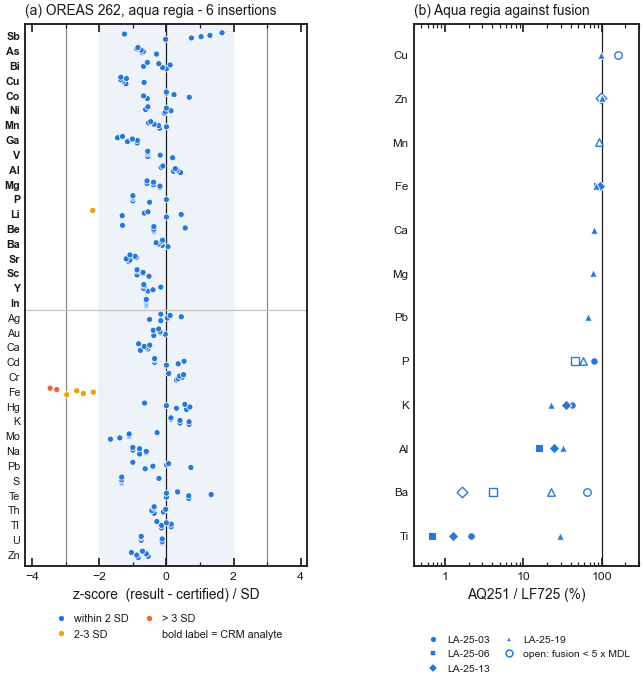

QC VERDICT
  Contamination (method blanks)
      evidence   : 47 of 53 analytes below the MDL in all 5 blanks; Cu, Pb, Zn, Ag, As, Sb at trace level, each < 1 % of the lowest sample
      consequence: no effect on any result
  Carry-over in preparation
      evidence   : 2 barren-sand washes at sand-level concentrations (Pb 1.07-1.3 ppm against > 1 % in most samples)
      consequence: no sign of carry-over
  Accuracy, aqua regia (OREAS 262)
      evidence   : 18 of 19 certified CRM analytes within 2 SD in all 6 runs (Li: warning (1 of 6 runs 2-3 SD)); Fe biased -8 % (z -3.5 to -2.2)
      consequence: accurate at the concentrations of the standard
  Accuracy at sample grades
      evidence   : standards carry Sb 3.45-5.06 ppm, Bi 0.98-23.5 ppm; samples P25-max: Sb 200 to > 2,000 ppm, Bi 53.6 to 673 ppm, As 534 to > 10,000 ppm
      consequence: NOT demonstrated for Sb, Bi and As at sample grades - no grade-bracketing standard
  Accuracy, fusion (SY-4, OREAS 73b, OREAS 133b)
      evid

In [9]:
# 6.6 QC figure
fig = plt.figure(figsize=(7.2, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1.0], wspace=0.42)

# (a) OREAS 262 z-scores, certified analytes; CRM analytes first
axz = fig.add_subplot(gs[0, 0])
cert = O262[O262["status"] == "C"].copy()
crm_first = [e for e in AQ_CRM + THESIS_EXTRA if e in cert["analyte"].unique()]
others = sorted(set(cert["analyte"]) - set(crm_first))
order = crm_first + others
ypos = {a: i for i, a in enumerate(order[::-1])}
axz.axvspan(-2, 2, color="#eef3fa", zorder=0)
for x in (-3, 3):
    axz.axvline(x, color=MUTED, lw=0.8, zorder=1)
axz.axvline(0, color=INK, lw=0.8, zorder=1)
for a, g in cert.groupby("analyte"):
    y = ypos[a] + np.linspace(-0.22, 0.22, len(g))
    col = np.where(np.abs(g["z"]) > 3, FLAG_COLOUR, np.where(np.abs(g["z"]) > 2, "#eda100", STATUS_COLOURS["blue"]))
    axz.scatter(g["z"], y, s=16, c=col, edgecolor="white", linewidth=0.5, zorder=3)
axz.set_yticks(list(ypos.values()))
axz.set_yticklabels(list(ypos.keys()), fontsize=7)
for t in axz.get_yticklabels():
    if t.get_text() in crm_first:
        t.set_fontweight("bold")
axz.axhline(len(others) - 0.5, color=HAIRLINE, lw=0.8)
axz.set_xlim(-4.2, 4.2)
axz.set_ylim(-0.8, len(order) - 0.2)
axz.set_xlabel("z-score  (result - certified) / SD")
axz.set_title("(a) OREAS 262, aqua regia - 6 insertions", loc="left", fontsize=9)
style_frame(axz, xminor=2, yminor=None)
axz.tick_params(axis="y", which="both", left=False, right=False)

# (b) aqua regia / fusion - filled: both values quantified; open: fusion value < 5 x MDL (indicative)
axr = fig.add_subplot(gs[0, 1])
xs = XMETHOD[XMETHOD["AQ_over_LF_pct"].notna() & ~XMETHOD["note"].str.contains("over-range")].copy()
elems = xs.groupby("element")["AQ_over_LF_pct"].median().sort_values().index.tolist()
yp = {e: i for i, e in enumerate(elems)}
mk = dict(zip(both_ids, ["o", "s", "D", "^"]))
for sid, g in xs.groupby("sample_id"):
    for clean, gg in g.groupby("clean"):
        axr.scatter(gg["AQ_over_LF_pct"], [yp[e] for e in gg["element"]], marker=mk[sid], s=24,
                    facecolor=STATUS_COLOURS["blue"] if clean else "white",
                    edgecolor="white" if clean else STATUS_COLOURS["blue"], linewidth=0.6 if clean else 0.9,
                    zorder=3)
axr.axvline(100, color=INK, lw=0.8)
axr.set_xscale("log")
axr.set_xlim(0.4, 300)
axr.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:g}"))
axr.set_yticks(list(yp.values())); axr.set_yticklabels(elems, fontsize=7.5)
axr.set_ylim(-0.7, len(elems) - 0.3)
axr.set_xlabel("AQ251 / LF725 (%)")
axr.set_title("(b) Aqua regia against fusion", loc="left", fontsize=9)
style_frame(axr, xminor=None, yminor=None)
axr.tick_params(axis="y", which="both", left=False, right=False)
h_s = [Line2D([], [], ls="", marker=mk[sid], ms=4.5, mfc=STATUS_COLOURS["blue"], mec="white", label=sid)
       for sid in both_ids]
h_s += [Line2D([], [], ls="", marker="o", ms=4.5, mfc="white", mec=STATUS_COLOURS["blue"],
               label="open: fusion < 5 x MDL")]
axr.legend(handles=h_s, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=2, fontsize=6.8,
           handletextpad=0.3, columnspacing=0.9)

handles = [Line2D([], [], ls="", marker="o", ms=4.5, mfc=STATUS_COLOURS["blue"], mec="white", label="within 2 SD"),
           Line2D([], [], ls="", marker="o", ms=4.5, mfc="#eda100", mec="white", label="2-3 SD"),
           Line2D([], [], ls="", marker="o", ms=4.5, mfc=FLAG_COLOUR, mec="white", label="> 3 SD"),
           Line2D([], [], ls="", marker="", label="bold label = CRM analyte")]
axz.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=7,
           handletextpad=0.2, columnspacing=0.9)
save_figure(fig, "Fig01_laboratory_QC")
plt.show()

# 6.7 verdict
_trace = BLANKS[BLANKS["n_above_MDL"] > 0]
_pb_pw = pw[(pw["analyte"] == "Pb") & (pw["q"] == "=")]["value"]
_cert_crm = O262_SUM[(O262_SUM["status"] == "C") & O262_SUM["is_crm"]]
_warn = _cert_crm[_cert_crm["verdict"] != "pass"]
_fe = O262_SUM.set_index("analyte").loc["Fe"]
_majors = FUSION_QC[FUSION_QC["analyte"].isin(["SiO2", "Al2O3", "Fe2O3", "MgO", "CaO", "K2O", "TiO2"])]
_la03 = DUPS[(DUPS["pair"] == "LA-25-03") & DUPS["analyte"].isin(AQ_CRM + THESIS_EXTRA) &
             (DUPS["mean_over_MDL"] >= 10)]
_b = BRACKET
_rng = lambda el: (f"{fmt_num(_b.loc[el, 'sample_P25'])} to "
                   + ("> " if el in set(over.index) else "") + f"{fmt_num(_b.loc[el, 'sample_max'])}")
QC_VERDICT = pd.DataFrame([
    ("Contamination (method blanks)",
     f"{int((BLANKS['n_above_MDL'] == 0).sum())} of {len(BLANKS)} analytes below the MDL in all 5 blanks; "
     f"{', '.join(_trace.index)} at trace level, each < {max(1, math.ceil(_trace['blank_pct_of_lowest_sample'].max()))} % "
     "of the lowest sample", "no effect on any result"),
    ("Carry-over in preparation",
     f"2 barren-sand washes at sand-level concentrations (Pb {fmt_num(_pb_pw.min())}-{fmt_num(_pb_pw.max())} ppm "
     "against > 1 % in most samples)", "no sign of carry-over"),
    ("Accuracy, aqua regia (OREAS 262)",
     f"{n_pass_crm} of {n_cert_crm} certified CRM analytes within 2 SD in all {o262['batch'].nunique()} runs"
     + (f" ({'; '.join(f'{r.analyte}: {r.verdict}' for r in _warn.itertuples())})" if len(_warn) else "")
     + f"; Fe biased {_fe['mean_bias_pct']:+.0f} % (z {_fe['z_min']:.1f} to {_fe['z_max']:.1f})",
     "accurate at the concentrations of the standard"),
    ("Accuracy at sample grades",
     f"standards carry Sb {fmt_num(min(_b.loc['Sb', ['OREAS262', 'BVGEO01_mean']]))}-{fmt_num(max(_b.loc['Sb', ['OREAS262', 'BVGEO01_mean']]))} ppm, "
     f"Bi {fmt_num(min(_b.loc['Bi', ['OREAS262', 'BVGEO01_mean']]))}-{fmt_num(max(_b.loc['Bi', ['OREAS262', 'BVGEO01_mean']]))} ppm; "
     f"samples P25-max: Sb {_rng('Sb')} ppm, Bi {_rng('Bi')} ppm, As {_rng('As')} ppm",
     "NOT demonstrated for Sb, Bi and As at sample grades - no grade-bracketing standard"),
    ("Accuracy, fusion (SY-4, OREAS 73b, OREAS 133b)",
     f"SiO2, Al2O3, Fe2O3, MgO, CaO, K2O, TiO2 within {_majors['bias_pct'].abs().max():.1f} % (one insertion each)",
     "accurate for the major oxides; minor oxides limited by the 0.01 % MDL"),
    ("Analytical precision",
     f"one Lagunazo pulp repeat (LA-25-03): RPD <= {_la03['RPD_pct'].max():.1f} % for every CRM analyte above 10 x MDL; "
     f"BVGEO01 median RSD {BVGEO['rsd_pct'].median():.1f} % (Sb {BVGEO.loc['Sb', 'rsd_pct']:.1f} %)",
     "good, but one pair is a check, not a precision estimate"),
    ("Sampling precision", "no field duplicates and no client-inserted blanks or standards identifiable in the export",
     "not quantified - state this limitation in the thesis"),
    ("Completeness",
     f"{n_is} samples insufficient for AQ251; Pb over-range in {len(pb_over)} samples, fusion Pb for {len(pb_follow)} of them; "
     f"Sb over-range in {int(CENSORING.loc['Sb', 'over_range'])} and As in {int(CENSORING.loc['As', 'over_range'])} without an ore-grade re-assay",
     "request ore-grade Sb, As and Pb before quoting maxima or Pb grades"),
    ("Digestion",
     f"aqua regia extracts {ti_rng['min']:.0f}-{ti_rng['max']:.0f} % of Ti and {al_rng['min']:.0f}-{al_rng['max']:.0f} % of Al "
     f"(fusion comparison, {len(both_ids)} samples)", "AQ251 lithophile CRMs are minimum values, not totals"),
], columns=["aspect", "evidence", "consequence"])
QC_VERDICT.to_csv(TAB_DIR / "T07_QC_verdict.csv", index=False, encoding="utf-8-sig")
print("QC VERDICT")
print("=" * 100)
for r in QC_VERDICT.itertuples():
    print(f"  {r.aspect}\n      evidence   : {r.evidence}\n      consequence: {r.consequence}")

## 7 · Sample locations

The `Locations` sheet holds 50 field points written as degree–minute–second strings with field IDs of the form `LG-25-nn`; the laboratory submission uses `LA-25-nn` for the same numbers. The checks below parse every string, normalise every ID, apply the explicit corrections of §1 (reporting each one), convert to UTM zone 29N, and look for duplicated IDs, duplicated coordinates, gaps in the number sequence and points that fall outside the surveyed area. Coordinates quoted to 0.1″ carry a rounding uncertainty of about ±1.5 m (northing) and ±1.2 m (easting), below handheld GNSS error.

The 2024 samples (`LA-24-nn`) are not in the sheet. Their coordinates are taken from `Lagunazo_UTM.csv` of the pXRF workflow when that file is present; otherwise they are listed as unlocated and left off the maps.

In [10]:
_DMS_RE = re.compile(r"""^\s*(\d+)\s*°\s*(\d+)\s*['′]\s*([\d.]+)\s*["″]\s*([NS])\s*[, ]\s*
                         (\d+)\s*°\s*(\d+)\s*['′]\s*([\d.]+)\s*["″]\s*([EW])\s*$""", re.X)


def parse_dms_pair(text):
    """'37°37'24.9"N 7°09'56.8"W' -> (lat, lon) in decimal degrees, or (nan, nan)."""
    m = _DMS_RE.match(str(text))
    if not m:
        return np.nan, np.nan
    d1, m1, s1, h1, d2, m2, s2, h2 = m.groups()
    lat = int(d1) + int(m1) / 60 + float(s1) / 3600
    lon = int(d2) + int(m2) / 60 + float(s2) / 3600
    return (-lat if h1 == "S" else lat), (-lon if h2 == "W" else lon)


ws = wb["Locations"]
loc_rows = [[c.value for c in r] for r in ws.iter_rows(min_row=2)]
LOC = pd.DataFrame([r[:3] for r in loc_rows if r[1] not in (None, "")], columns=["No", "ID_recorded", "DMS"])
LOC["No"] = LOC["No"].astype(int)
LOC[["lat", "lon"]] = LOC["DMS"].apply(lambda s: pd.Series(parse_dms_pair(s)))
_ids = LOC["ID_recorded"].apply(canonical_id)
LOC["ID_normalised"] = [i for i, _ in _ids]
LOC["ID_note"] = [n for _, n in _ids]
LOC["ID_final"] = LOC["ID_normalised"]
LOC["correction"] = ""
LOC["correction_basis"] = ""
for no, (rec, new, basis) in LOCATION_ID_CORRECTIONS.items():
    m = LOC["No"] == no
    if not m.any() or LOC.loc[m, "ID_recorded"].iloc[0] != rec:
        print(f"  !! correction for row {no} skipped: recorded ID is not '{rec}'")
        continue
    LOC.loc[m, "correction_basis"] = basis
    if APPLY_PROBABLE_ID_CORRECTIONS:
        LOC.loc[m, "ID_final"] = new
        LOC.loc[m, "correction"] = f"probable: {rec} -> {new}"
    else:
        LOC.loc[m, "correction"] = f"NOT applied (probable {rec} -> {new})"

to_utm = Transformer.from_crs(CRS_GEOGRAPHIC, CRS_PROJECTED, always_xy=True)
LOC["E"], LOC["N"] = to_utm.transform(LOC["lon"].to_numpy(), LOC["lat"].to_numpy())
LOC["source"] = "ICP workbook, Locations sheet"

# checks
flags = {i: [] for i in LOC.index}
for i in LOC.index[LOC["lat"].isna()]:
    flags[i].append("coordinate not parsed")
for i, r in LOC.iterrows():
    if r["ID_note"] not in ("ok", "LG->LA prefix"):
        flags[i].append(f"ID format: {r['ID_note'].replace('LG->LA prefix, ', '').replace(', LG->LA prefix', '')}")
    if r["correction"]:
        flags[i].append(r["correction"])
dup_id = LOC[LOC["ID_final"].duplicated(keep=False)]
for i in dup_id.index:
    flags[i].append("duplicate ID")
dup_xy = LOC[LOC.duplicated(["E", "N"], keep=False)]
for i in dup_xy.index:
    others = ", ".join(dup_xy.loc[dup_xy.index != i, "ID_final"])
    flags[i].append(f"identical coordinate to {others}")
xy = LOC[["E", "N"]].to_numpy()
dmat = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1])
np.fill_diagonal(dmat, np.inf)
LOC["nearest_m"] = dmat.min(axis=1)
LOC["nearest_ID"] = LOC["ID_final"].to_numpy()[dmat.argmin(axis=1)]
cen = np.median(xy, axis=0)
dist = np.hypot(*(xy - cen).T)
mad = np.median(np.abs(dist - np.median(dist)))
LOC["dist_from_centre_m"] = dist
for i in LOC.index[dist > np.median(dist) + 5 * 1.4826 * mad]:
    flags[i].append("far from the other points")
LOC["flags"] = ["; ".join(v) for v in (flags[i] for i in LOC.index)]

# number-sequence completeness (2025 field points)
nums = LOC.loc[LOC["ID_final"].str.startswith("LA-25-"), "ID_final"].str[-2:].astype(int)
full = set(range(1, nums.max() + 1))
missing_nums, repeated_nums = sorted(full - set(nums)), sorted(nums[nums.duplicated()].unique())

# pXRF survey frame
if PXRF_COORDS_FILE is not None:
    _pc = pd.read_csv(PXRF_COORDS_FILE)
    _pc.columns = [c.strip() for c in _pc.columns]
    PXRF_EXTENT = dict(xmin=_pc["X"].min(), xmax=_pc["X"].max(), ymin=_pc["Y"].min(), ymax=_pc["Y"].max())
    extent_src = f"{PXRF_COORDS_FILE.name} ({len(_pc)} points)"
else:
    PXRF_EXTENT, extent_src = PXRF_EXTENT_REFERENCE, "Final_XRF_samples_mapping_r3 printout (87 points)"
buf = 100.0
outside = LOC[(LOC["E"] < PXRF_EXTENT["xmin"] - buf) | (LOC["E"] > PXRF_EXTENT["xmax"] + buf) |
              (LOC["N"] < PXRF_EXTENT["ymin"] - buf) | (LOC["N"] > PXRF_EXTENT["ymax"] + buf)]

print("LOCATION CHECKS")
print("-" * 100)
print(f"  Points in the Locations sheet  : {len(LOC)}; coordinates parsed: {int(LOC['lat'].notna().sum())}")
print(f"  Extent (UTM 29N)               : E {LOC['E'].min():,.0f}-{LOC['E'].max():,.0f} m, "
      f"N {LOC['N'].min():,.0f}-{LOC['N'].max():,.0f} m "
      f"({LOC['E'].max() - LOC['E'].min():.0f} m x {LOC['N'].max() - LOC['N'].min():.0f} m)")
print(f"  pXRF survey frame              : E {PXRF_EXTENT['xmin']:,.0f}-{PXRF_EXTENT['xmax']:,.0f}, "
      f"N {PXRF_EXTENT['ymin']:,.0f}-{PXRF_EXTENT['ymax']:,.0f}  [{extent_src}]")
print(f"  Points > {buf:.0f} m outside that frame: {len(outside)}"
      + (f" ({', '.join(outside['ID_final'])})" if len(outside) else " - the ICP points lie on the same waste facility"))
print(f"  Nearest-neighbour spacing      : median {LOC['nearest_m'].median():.0f} m, "
      f"min {LOC['nearest_m'].min():.1f} m, max {LOC['nearest_m'].max():.0f} m")
print(f"  2025 numbers 01-{nums.max():02d}         : missing {missing_nums or 'none'}, repeated {repeated_nums or 'none'}"
      + ("  (complete and unique after the corrections)" if not missing_nums and not repeated_nums else ""))
print("\n  Rows with a flag:")
print(LOC.loc[LOC["flags"] != "", ["No", "ID_recorded", "ID_final", "DMS", "nearest_m", "flags"]]
      .round(1).to_string(index=False))

# optional: 2024 samples from the pXRF coordinate table 
EXTRA = pd.DataFrame(columns=["ID_final", "E", "N", "source"])
if PXRF_COORDS_FILE is not None:
    _pc["ID_final"] = [canonical_id(str(v).replace("_", "-"))[0] for v in _pc["ID"]]
    wanted = set(INVENTORY["sample_id"]) - set(LOC["ID_final"])
    EXTRA = (_pc[_pc["ID_final"].isin(wanted)].drop_duplicates("ID_final")
             .rename(columns={"X": "E", "Y": "N"})[["ID_final", "E", "N"]])
    EXTRA["source"] = f"{PXRF_COORDS_FILE.name} (pXRF workflow)"
    both = set(_pc["ID_final"]) & set(LOC["ID_final"])
    if both:
        chk = (LOC.set_index("ID_final").loc[sorted(both), ["E", "N"]]
               .join(_pc.drop_duplicates("ID_final").set_index("ID_final")[["X", "Y"]]))
        chk["offset_m"] = np.hypot(chk["E"] - chk["X"], chk["Y"] - chk["N"])
        print(f"\n  IDs present in both coordinate sources: {len(both)}; offsets > 10 m: "
              f"{', '.join(chk.index[chk['offset_m'] > 10]) or 'none'}")
    print(f"\n  {len(EXTRA)} laboratory samples located from {PXRF_COORDS_FILE.name}: {', '.join(EXTRA['ID_final'])}")

# join with the laboratory samples
XY = pd.concat([LOC[["ID_final", "E", "N", "source", "flags"]], EXTRA.assign(flags="")], ignore_index=True)
XY = XY.drop_duplicates("ID_final", keep="first").set_index("ID_final")
SAMPLES = INVENTORY.set_index("sample_id").join(XY, how="left")
SAMPLES["located"] = SAMPLES["E"].notna()

# waste type: pXRF table first, then manual overrides
SAMPLES["waste_type"] = pd.Series(dtype="object")
if PXRF_WASTE_FILE is not None:
    _w = pd.read_csv(PXRF_WASTE_FILE)
    _w.columns = [c.strip() for c in _w.columns]
    _w["ID_final"] = [canonical_id(str(v).replace("_", "-"))[0] for v in _w["Sample"]]
    _w["wt"] = _w["Type"].astype(str).str.lower().map(lambda s: "slag" if "slag" in s else
                                                       ("tailings" if "tail" in s else np.nan))
    SAMPLES["waste_type"] = SAMPLES.index.map(_w.drop_duplicates("ID_final").set_index("ID_final")["wt"])
for k, v in WASTE_TYPE_OVERRIDES.items():
    if k in SAMPLES.index:
        SAMPLES.loc[k, "waste_type"] = v

unlocated = SAMPLES[~SAMPLES["located"]]
print("\nLABORATORY SAMPLES AND COORDINATES")
print("-" * 100)
for pk in ["AQ251", "LF725"]:
    rep = SAMPLES[SAMPLES[pk] == "reported"]
    print(f"  {pk} results: {len(rep)}; with coordinates: {int(rep['located'].sum())}; without: "
          f"{', '.join(rep.index[~rep['located']]) or 'none'}")
not_in_export = sorted(set(LOC["ID_final"]) - set(SAMPLES.index))
print(f"  Field points with no sample in this export: {len(not_in_export)} ({', '.join(not_in_export)})")
print(f"  Waste type known for {int(SAMPLES['waste_type'].notna().sum())} of {len(SAMPLES)} samples "
      "(source: pXRF waste-type table and WASTE_TYPE_OVERRIDES) [CONFIRM for the LA-25 samples]")

LOC.to_csv(TAB_DIR / "T08_location_checks.csv", index=False, encoding="utf-8-sig")
SAMPLES.to_csv(TAB_DIR / "T09_samples_with_coordinates.csv", encoding="utf-8-sig")
print("\nSaved: T08_location_checks.csv, T09_samples_with_coordinates.csv")

LOCATION CHECKS
----------------------------------------------------------------------------------------------------
  Points in the Locations sheet  : 50; coordinates parsed: 50
  Extent (UTM 29N)               : E 661,436-661,976 m, N 4,165,391-4,165,792 m (539 m x 401 m)
  pXRF survey frame              : E 661,445-661,930, N 4,165,390-4,165,819  [Lagunazo_UTM.csv (87 points)]
  Points > 100 m outside that frame: 0 - the ICP points lie on the same waste facility
  Nearest-neighbour spacing      : median 22 m, min 0.0 m, max 57 m
  2025 numbers 01-50         : missing none, repeated none  (complete and unique after the corrections)

  Rows with a flag:
 No ID_recorded ID_final                      DMS  nearest_m                                                             flags
  2    Lg-25-41 LA-25-41 37°37'24.1"N 7°09'55.8"W       34.8                                            ID format: letter case
 13    LG-35-31 LA-25-31 37°37'28.0"N 7°10'01.5"W       44.9  ID format: implausibl

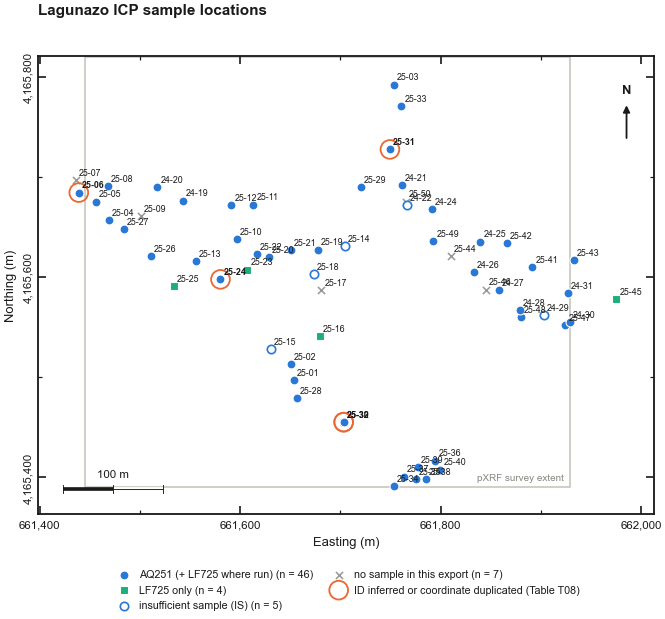

In [11]:
# location map
try:
    from adjustText import adjust_text
except ImportError:
    adjust_text = None

ALL_PTS = XY.copy()
ALL_PTS["status"] = "no sample in this export"
for sid, r in SAMPLES[SAMPLES["located"]].iterrows():
    if r["AQ251"] == "reported":
        ALL_PTS.loc[sid, "status"] = "AQ251 (+ LF725 where run)"
    elif r["LF725"] == "reported":
        ALL_PTS.loc[sid, "status"] = "LF725 only"
    elif r["AQ251"].startswith("insufficient"):
        ALL_PTS.loc[sid, "status"] = "insufficient sample (IS)"


def map_extent(xs, ys, pad=0.07, min_aspect=0.62):
    """Common map frame (UTM metres) with padding; returns (xmin, xmax, ymin, ymax)."""
    x0, x1, y0, y1 = np.nanmin(xs), np.nanmax(xs), np.nanmin(ys), np.nanmax(ys)
    w, h = x1 - x0, y1 - y0
    if h < min_aspect * w:
        extra = (min_aspect * w - h) / 2; y0 -= extra; y1 += extra; h = y1 - y0
    return (x0 - pad * w, x1 + pad * w, y0 - pad * h, y1 + pad * h)


EXTENT = map_extent(ALL_PTS["E"], ALL_PTS["N"])
EXT_W, EXT_H = EXTENT[1] - EXTENT[0], EXTENT[3] - EXTENT[2]


def add_basemap(ax):
    if not USE_BASEMAP:
        return
    try:
        import contextily as ctx
        ctx.add_basemap(ax, crs=CRS_PROJECTED, source=ctx.providers.Esri.WorldImagery,
                        attribution_size=5, zorder=0)
        ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    except Exception as exc:                     # no internet or no contextily: plain background
        print(f"  basemap skipped ({type(exc).__name__})")


STATUS_STYLE = {
    "AQ251 (+ LF725 where run)": dict(marker="o", s=34, fc=STATUS_COLOURS["blue"], ec="white", lw=0.7),
    "LF725 only": dict(marker="s", s=34, fc=STATUS_COLOURS["aqua"], ec="white", lw=0.7),
    "insufficient sample (IS)": dict(marker="o", s=30, fc="white", ec=STATUS_COLOURS["blue"], lw=1.1),
    "no sample in this export": dict(marker="x", s=22, fc=STATUS_COLOURS["grey"], ec=STATUS_COLOURS["grey"], lw=1.0),
}

fig_w = 6.6
ax_w = 5.6
ax_h = ax_w * EXT_H / EXT_W
fig_h = ax_h + 1.65
fig = plt.figure(figsize=(fig_w, fig_h))
ax = fig.add_axes([0.105, 1.05 / fig_h, ax_w / fig_w, ax_h / fig_h])
add_basemap(ax)
ax.add_patch(plt.Rectangle((PXRF_EXTENT["xmin"], PXRF_EXTENT["ymin"]), PXRF_EXTENT["xmax"] - PXRF_EXTENT["xmin"],
                           PXRF_EXTENT["ymax"] - PXRF_EXTENT["ymin"], fill=False, ec=HAIRLINE, lw=1.0, zorder=1))
ax.text(PXRF_EXTENT["xmax"] - 0.01 * EXT_W, PXRF_EXTENT["ymin"] + 0.012 * EXT_H, "pXRF survey extent",
        ha="right", va="bottom", fontsize=6.5, color=MUTED)
for st, sty in STATUS_STYLE.items():
    g = ALL_PTS[ALL_PTS["status"] == st]
    if g.empty:
        continue
    if sty["marker"] == "x":
        ax.scatter(g["E"], g["N"], marker="x", s=sty["s"], c=sty["fc"], linewidths=sty["lw"], zorder=3,
                   label=f"{st} (n = {len(g)})")
    else:
        ax.scatter(g["E"], g["N"], marker=sty["marker"], s=sty["s"], facecolor=sty["fc"], edgecolor=sty["ec"],
                   linewidths=sty["lw"], zorder=4, label=f"{st} (n = {len(g)})")
flagged = ALL_PTS[ALL_PTS["flags"].str.contains("probable|identical", na=False)]
ax.scatter(flagged["E"], flagged["N"], s=150, facecolor="none", edgecolor=FLAG_COLOUR, linewidths=1.2, zorder=5,
           label="ID inferred or coordinate duplicated (Table T08)")
texts = []
for sid, r in ALL_PTS.iterrows():
    lab = sid.replace("LA-", "")
    bold = sid in flagged.index
    texts.append(ax.text(r["E"], r["N"], lab, fontsize=5.8, color=INK, zorder=6,
                         fontweight="bold" if bold else "normal", ha="left", va="bottom"))
if adjust_text is not None:
    adjust_text(texts, ax=ax, expand=(1.15, 1.3), arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.4))
else:
    for t in texts:
        t.set_position((t.get_position()[0] + 3, t.get_position()[1] + 3))
ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
ax.set_aspect("equal", adjustable="box")
style_frame(ax); utm_axes(ax)
add_north_arrow(ax); add_scale_bar(ax)
fig.text(0.105, 1 - 0.12 / fig_h, "Lagunazo ICP sample locations",
         fontsize=10, fontweight="bold", va="top")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=7, handletextpad=0.4,
          columnspacing=1.4, scatterpoints=1)
save_figure(fig, "Fig02_sample_locations")
plt.show()
n_la24 = int((~SAMPLES["located"] & (SAMPLES["AQ251"] == "reported")).sum())
if n_la24:
    print(f"Not shown: {n_la24} LA-24 samples with AQ251 results and no coordinates in the ICP workbook "
          "(add Lagunazo_UTM.csv to data/ to place them).")

## 8 · Critical raw materials: coverage and statistics

First the coverage: which of the 34 Annex II entries the two laboratory packages can speak to at all. Then the statistics for every CRM analyte, computed on all samples with a result (not only the located ones), with censoring handled explicitly:

* percentiles are order statistics of the full set of results with non-detects ranked lowest and over-range results ranked highest, so a percentile that falls among the non-detects is reported as `<MDL` and one that falls among the over-range results as `≥` the upper limit, never as a substituted number (Helsel, 2012);
* the mean is given only where at least 80 % of results are quantified, and as a lower bound (non-detects at zero, over-range at the limit);
* the ratio to upper continental crust (× UCC) is given only for digestion classes A and F, where the measured value approximates the total. For class B elements the aqua regia value is a minimum and a ratio to a total-rock background would understate the material.

In [12]:
def element_data(method, analyte, sample_ids):
    """Results of one analyte for the given samples, indexed by sample_id, with coordinates."""
    g = A[(A["method"] == method) & (A["analyte"] == analyte) & A["sample_id"].isin(sample_ids)]
    g = g.set_index("sample_id")[["q", "raw", "value", "unit", "mdl", "value_ppm", "mdl_ppm", "element",
                                  "element_ppm", "element_mdl_ppm"]]
    return g.join(SAMPLES[["E", "N", "located", "waste_type"]], how="left")


def censored_stats(q, v, mdl):
    """Percentiles and mean with explicit censoring. q: qualifiers, v: values, mdl: detection limit."""
    q = np.asarray(q); v = np.asarray(v, float)
    n = len(v); n_lt = int((q == "<").sum()); n_gt = int((q == ">").sum())
    lb = np.where(q == "<", 0.0, v)
    order = np.sort(lb)
    out = dict(n=n, n_quantified=int((q == "=").sum()), n_below_MDL=n_lt, n_over_range=n_gt,
               detection_pct=100 * (n - n_lt) / n if n else np.nan, MDL=mdl)
    for p in (10, 25, 50, 75, 90):
        pos = p / 100 * (n - 1)
        lo, hi = int(np.floor(pos)), int(np.ceil(pos))
        if lo < n_lt:
            out[f"P{p}"], out[f"P{p}_flag"] = mdl, "<"
        elif hi > n - n_gt - 1:
            out[f"P{p}"], out[f"P{p}_flag"] = order[hi], ">="
        else:
            out[f"P{p}"], out[f"P{p}_flag"] = float(np.percentile(lb, p)), ""
    det = v[q != "<"]
    out["min_quantified"] = float(np.min(v[q == "="])) if (q == "=").any() else np.nan
    out["max"] = float(np.max(det)) if len(det) else mdl
    out["max_flag"] = ">" if n_gt else ("<" if not len(det) else "")
    out["mean_lower_bound"] = float(lb.mean()) if out["detection_pct"] >= 80 else np.nan
    return out


def fmt_stat(val, flag):
    if flag == "<":
        return f"<{fmt_num(val)}"
    if flag in (">", ">="):
        return f"≥{fmt_num(val)}"
    return fmt_num(val)


# coverage of Annex II
cov = []
for entry, strategic, meas, note in CRMA_ENTRIES:
    cov.append(dict(annex_II_entry=entry, annex_I_strategic=strategic or "-",
                    measured_as=", ".join(f"{a} ({m})" for m, a in meas) or "not measurable with AQ251/LF725",
                    note=note))
COVERAGE = pd.DataFrame(cov)
print("REGULATION (EU) 2024/1252 - COVERAGE BY THE TWO LABORATORY PACKAGES")
print("-" * 118)
print(COVERAGE.to_string(index=False))

# statistics, AQ251
st_rows = []
for el in AQ_CRM + THESIS_EXTRA:
    d = element_data("AQ251", el, AQ_SAMPLES)
    s = censored_stats(d["q"], d["value_ppm"], float(d["mdl_ppm"].iloc[0]))
    cls = DIGESTION_CLASS[el]
    ucc = UCC_PPM.get(el, np.nan)
    ratio_ok = cls == "A" and np.isfinite(ucc)
    st_rows.append(dict(element=el, name=ELEMENT_NAME[el], status=crma_status(el), method="AQ251",
                        digestion=f"{cls}: {DIGESTION_LABEL[cls]}", unit_reported=d["unit"].iloc[0], **s,
                        n_located=int(d["located"].sum()), UCC_ppm=ucc,
                        median_x_UCC=(s["P50"] / ucc) if (ratio_ok and s["P50_flag"] == "") else np.nan,
                        P90_x_UCC=(s["P90"] / ucc) if (ratio_ok and s["P90_flag"] == "") else np.nan))
CRM_STATS = pd.DataFrame(st_rows).set_index("element")

# statistics, LF725 (fusion totals; element-equivalent ppm)
lf_rows = []
for an in LF_CRM:
    d = element_data("LF725", an, LF_SAMPLES)
    el = d["element"].iloc[0]
    s = censored_stats(d["q"], d["element_ppm"], float(d["element_mdl_ppm"].iloc[0]))
    ucc = UCC_PPM.get(el, np.nan)
    lf_rows.append(dict(element=f"{an} (LF725)", name=ELEMENT_NAME.get(el, el), status=crma_status(el),
                        method="LF725", digestion="F: total (fusion)", unit_reported="% (as element ppm here)",
                        **s, n_located=int(d["located"].sum()), UCC_ppm=ucc,
                        median_x_UCC=s["P50"] / ucc if s["P50_flag"] == "" else np.nan,
                        P90_x_UCC=s["P90"] / ucc if s["P90_flag"] == "" else np.nan))
LF_STATS = pd.DataFrame(lf_rows).set_index("element")


def print_stats(tab, title):
    print(f"\n{title}")
    print("-" * 118)
    print(f"  {'El':<14}{'status':<19}{'dig.':<6}{'n':>3}{'det%':>6}{'min':>9}{'P25':>9}{'median':>9}{'P75':>9}"
          f"{'P90':>9}{'max':>10}{'mean>=':>9}{'xUCC':>8}")
    for el, r in tab.iterrows():
        print(f"  {el:<14}{r['status']:<19}{r['digestion'][0]:<6}{r['n']:>3}{r['detection_pct']:>6.0f}"
              f"{fmt_num(r['min_quantified']):>9}{fmt_stat(r['P25'], r['P25_flag']):>9}"
              f"{fmt_stat(r['P50'], r['P50_flag']):>9}{fmt_stat(r['P75'], r['P75_flag']):>9}"
              f"{fmt_stat(r['P90'], r['P90_flag']):>9}{fmt_stat(r['max'], r['max_flag']):>10}"
              f"{fmt_num(r['mean_lower_bound']):>9}{fmt_num(r['median_x_UCC']):>8}")


print_stats(CRM_STATS, f"CRM STATISTICS - AQ251 aqua regia, all {n_aq} samples with a result (ppm)")
print("  digestion A = near-total, B = partial (minimum values), C = screening only; xUCC only for A.")
print("  In is a thesis target element, not on the 2024 lists.")
print_stats(LF_STATS, f"CRM STATISTICS - LF725 fusion (total), {n_lf} samples (element ppm)")

CRM_STATS.to_csv(TAB_DIR / "T10_CRM_statistics_AQ251.csv", encoding="utf-8-sig")
LF_STATS.to_csv(TAB_DIR / "T11_CRM_statistics_LF725.csv", encoding="utf-8-sig")
COVERAGE.to_csv(TAB_DIR / "T12_CRMA2024_coverage.csv", index=False, encoding="utf-8-sig")
print("\nSaved: T10_CRM_statistics_AQ251.csv, T11_CRM_statistics_LF725.csv, T12_CRMA2024_coverage.csv")

REGULATION (EU) 2024/1252 - COVERAGE BY THE TWO LABORATORY PACKAGES
----------------------------------------------------------------------------------------------------------------------
           annex_II_entry                                annex_I_strategic                     measured_as                                                              note
                 Antimony                                                -                      Sb (AQ251)                                                                  
                  Arsenic                                                -                      As (AQ251)             also the governing health constraint on this material
Bauxite/alumina/aluminium                        Bauxite/alumina/aluminium       Al (AQ251), Al2O3 (LF725)                     Al is a proxy only - the waste is not bauxite
                   Baryte                                                -          Ba (AQ251), Ba (LF725)          barit

C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
  fig.savefig(p)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
 

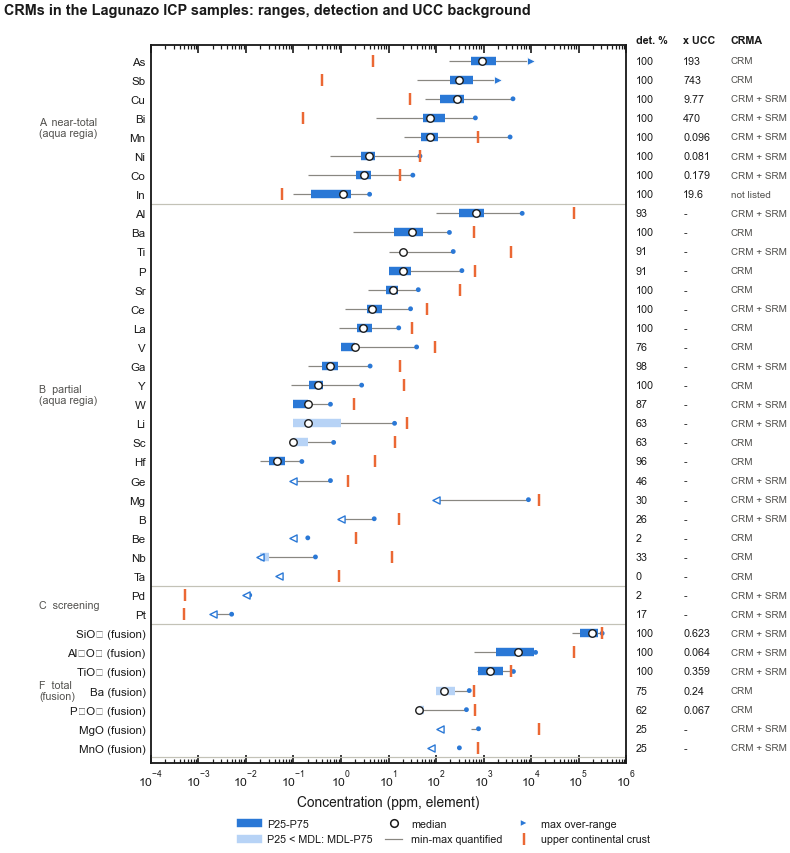

In [13]:
# Figure 3: concentration ranges of every CRM analyte against crustal background
rows = []
for el, r in CRM_STATS.iterrows():
    rows.append((el, "AQ251", DIGESTION_CLASS[el], r))
for el, r in LF_STATS.iterrows():
    rows.append((el.replace(" (LF725)", ""), "LF725", "F", r))
grp_order = {"A": 0, "B": 1, "C": 2, "F": 3}
rows.sort(key=lambda t: (grp_order[t[2]], -(t[3]["P50"] if t[3]["P50_flag"] == "" else 0)))

_fh = 0.175 * len(rows) + 1.45
fig, ax = plt.subplots(figsize=(7.2, _fh))
fig.subplots_adjust(left=0.2, right=0.8, top=1 - 0.5 / _fh, bottom=0.9 / _fh)
BLUE, LIGHT = STATUS_COLOURS["blue"], "#b7d3f6"
yt, ylab = [], []
for i, (lab, meth, cls, r) in enumerate(rows):
    y = len(rows) - 1 - i
    unit_el = OXIDE_TO_ELEMENT.get(lab, (lab,))[0]
    lo_full = r["min_quantified"] if np.isfinite(r["min_quantified"]) else r["MDL"]
    ax.plot([lo_full, r["max"]], [y, y], color=MUTED, lw=0.8, zorder=2, solid_capstyle="butt")
    p25 = r["P25"]; p75 = r["P75"]
    if r["P25_flag"] == "<" and r["P75_flag"] == "<":
        pass
    elif r["P25_flag"] == "<":
        ax.plot([r["MDL"], p75], [y, y], color=LIGHT, lw=5.5, solid_capstyle="butt", zorder=3)
    else:
        ax.plot([p25, p75], [y, y], color=BLUE, lw=5.5, solid_capstyle="butt", zorder=3)
    if r["P50_flag"] == "<":
        ax.scatter([r["MDL"]], [y], marker="<", s=22, facecolor="white", edgecolor=BLUE, lw=0.9, zorder=5)
    else:
        ax.scatter([r["P50"]], [y], marker="o", s=24, facecolor="white", edgecolor=INK, lw=0.9, zorder=5)
    if r["max_flag"] == ">":
        ax.scatter([r["max"]], [y], marker=">", s=26, facecolor=BLUE, edgecolor="white", lw=0.5, zorder=5)
    elif r["max_flag"] != "<":
        ax.scatter([r["max"]], [y], marker="o", s=10, facecolor=BLUE, edgecolor="none", zorder=4)
    ucc = UCC_PPM.get(unit_el)
    if ucc:
        ax.scatter([ucc], [y], marker="|", s=70, color=FLAG_COLOUR, linewidths=1.6, zorder=6)
    yt.append(y)
    _sub = str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉")
    ylab.append((lab.translate(_sub) + " (fusion)") if meth == "LF725" else lab)
    ax.text(1.02, y, f"{r['detection_pct']:.0f}", transform=ax.get_yaxis_transform(), ha="left", va="center",
            fontsize=7, color=INK)
    xu = r["median_x_UCC"]
    ax.text(1.12, y, fmt_num(xu) if np.isfinite(xu) else "-", transform=ax.get_yaxis_transform(),
            ha="left", va="center", fontsize=7, color=INK)
    ax.text(1.22, y, crma_status(unit_el).replace("not listed (2024)", "not listed"),
            transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=6.5, color=INK_SOFT)
ax.set_yticks(yt); ax.set_yticklabels(ylab, fontsize=7.5)
ax.set_xscale("log"); ax.set_xlim(1e-4, 1e6)
ax.set_ylim(-0.8, len(rows) - 0.2)
ax.set_xlabel("Concentration (ppm, element)")
style_frame(ax, xminor=None, yminor=None)
ax.tick_params(axis="y", which="both", left=False, right=False)
ax.xaxis.set_major_locator(LogLocator(base=10, numticks=12))
ax.xaxis.set_minor_formatter(NullFormatter())
bounds = {}
for i, (_, _, cls, _) in enumerate(rows):
    bounds.setdefault(cls, []).append(len(rows) - 1 - i)
names = {"A": "A  near-total\n(aqua regia)", "B": "B  partial\n(aqua regia)", "C": "C  screening", "F": "F  total\n(fusion)"}
for cls, ys in bounds.items():
    ax.axhline(min(ys) - 0.5, color=HAIRLINE, lw=0.8)
    ax.text(-0.235, np.mean(ys), names[cls], transform=ax.get_yaxis_transform(), ha="left", va="center",
            fontsize=7, color=INK_SOFT, rotation=0)
for x, t in ((1.02, "det. %"), (1.12, "x UCC"), (1.22, "CRMA")):
    ax.text(x, len(rows) - 0.2, t, transform=ax.get_yaxis_transform(), ha="left", va="bottom", fontsize=7,
            fontweight="bold")
leg = [Line2D([], [], color=BLUE, lw=5.5, label="P25-P75"),
       Line2D([], [], color=LIGHT, lw=5.5, label="P25 < MDL: MDL-P75"),
       Line2D([], [], marker="o", ls="", mfc="white", mec=INK, ms=5, label="median"),
       Line2D([], [], color=MUTED, lw=0.8, label="min-max quantified"),
       Line2D([], [], marker=">", ls="", mfc=BLUE, mec="white", ms=5.5, label="max over-range"),
       Line2D([], [], marker="|", ls="", mec=FLAG_COLOUR, ms=8, mew=1.6, label="upper continental crust")]
ax.legend(handles=leg, loc="upper center", bbox_to_anchor=(0.62, -0.42 / (_fh * (1 - 1.4 / _fh))), ncol=3, fontsize=7,
          handlelength=1.6, columnspacing=1.2)
fig.text(0.015, 0.985, "CRMs in the Lagunazo ICP samples: ranges, detection and UCC background",
         ha="left", va="top", fontsize=9.5, fontweight="bold")
save_figure(fig, "Fig03_CRM_concentration_ranges")
plt.show()

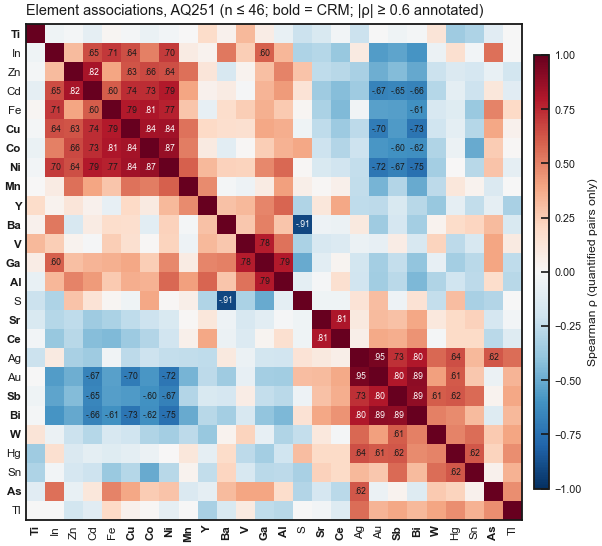

SELECTED ASSOCIATIONS (Spearman rho, quantified pairs)
----------------------------------------------------------------------
  Sb-Bi  rho = +0.89   (n = 44)
  Sb-Au  rho = +0.80   (n = 44)
  Bi-Au  rho = +0.89   (n = 46)
  Sb-Ag  rho = +0.73   (n = 27)
  Bi-Cu  rho = -0.73   (n = 46)
  Sb-Cu  rho = -0.57   (n = 44)
  Cu-Co  rho = +0.84   (n = 46)
  Cu-Ni  rho = +0.84   (n = 46)
  Co-Ni  rho = +0.87   (n = 46)
  Cu-Fe  rho = +0.79   (n = 46)
  In-Cu  rho = +0.64   (n = 46)
  As-Sb  rho = +0.03   (n = 43)
  As-Bi  rho = -0.13   (n = 45)

  Left out (quantified in < 50 % of samples): none; Pb is over-range in 42 of 46 samples and cannot be ranked.


In [14]:
# Figure 4: element associations (Spearman, detected-only pairwise)
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

ASSOC = ["Sb", "Bi", "As", "Cu", "Co", "Ni", "Mn", "In", "Ga", "W", "V", "Ti", "Al", "Ba", "Sr", "Y", "Ce",
         "Fe", "S", "Zn", "Cd", "Ag", "Au", "Hg", "Sn", "Tl"]
wide_q = A[(A["method"] == "AQ251") & A["sample_id"].isin(AQ_SAMPLES)].pivot(index="sample_id", columns="analyte",
                                                                                values="q")
wide_v = A[(A["method"] == "AQ251") & A["sample_id"].isin(AQ_SAMPLES)].pivot(index="sample_id", columns="analyte",
                                                                                values="value")
DET = wide_v.where(wide_q == "=")[ASSOC]            # quantified values only (her pXRF convention)
keep = [e for e in ASSOC if DET[e].notna().mean() >= 0.5]
RHO = pd.DataFrame(np.nan, index=keep, columns=keep); NPAIR = RHO.copy()
for a in keep:
    for b in keep:
        m = DET[a].notna() & DET[b].notna()
        NPAIR.loc[a, b] = m.sum()
        if m.sum() >= 10:
            RHO.loc[a, b] = sps.spearmanr(DET.loc[m, a], DET.loc[m, b])[0]
Z = linkage(squareform((1 - RHO.fillna(0).to_numpy()).clip(0), checks=False), method="average")
ordr = [keep[i] for i in leaves_list(Z)]
R = RHO.loc[ordr, ordr]

fig, ax = plt.subplots(figsize=(7.0, 6.4))
im = ax.imshow(R.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(ordr))); ax.set_yticks(range(len(ordr)))
crm_set = set(AQ_CRM)
ax.set_xticklabels(ordr, fontsize=7.5, rotation=90); ax.set_yticklabels(ordr, fontsize=7.5)
for t in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
    if t.get_text() in crm_set:
        t.set_fontweight("bold")
for i in range(len(ordr)):
    for j in range(len(ordr)):
        v = R.iat[i, j]
        if i != j and np.isfinite(v) and abs(v) >= 0.6:
            ax.text(j, i, f"{v:.2f}".replace("0.", "."), ha="center", va="center", fontsize=5.6,
                    color="white" if abs(v) >= 0.8 else INK)
for s in ax.spines.values():
    s.set_linewidth(1.2); s.set_color(INK)
ax.tick_params(which="both", length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02, aspect=28)
cb.set_label("Spearman ρ (quantified pairs only)", fontsize=8); cb.ax.tick_params(labelsize=7)
ax.set_title(f"Element associations, AQ251 (n ≤ {n_aq}; bold = CRM; |ρ| ≥ 0.6 annotated)",
             loc="left", fontsize=9.5)
save_figure(fig, "Fig04_element_associations")
plt.show()

pairs = [("Sb", "Bi"), ("Sb", "Au"), ("Bi", "Au"), ("Sb", "Ag"), ("Bi", "Cu"), ("Sb", "Cu"), ("Cu", "Co"),
         ("Cu", "Ni"), ("Co", "Ni"), ("Cu", "Fe"), ("In", "Cu"), ("As", "Sb"), ("As", "Bi")]
print("SELECTED ASSOCIATIONS (Spearman rho, quantified pairs)")
print("-" * 70)
for a, b in pairs:
    if a in R.index and b in R.index:
        print(f"  {a:>2}-{b:<2}  rho = {RHO.loc[a, b]:+.2f}   (n = {int(NPAIR.loc[a, b])})")
not_in = [e for e in ASSOC if e not in keep]
print(f"\n  Left out (quantified in < 50 % of samples): {', '.join(not_in) or 'none'}; Pb is over-range in "
      f"{int(CENSORING.loc['Pb', 'over_range'])} of {n_aq} samples and cannot be ranked.")
RHO.round(3).to_csv(TAB_DIR / "T13_spearman_AQ251.csv", encoding="utf-8-sig")

## 9 · Maps of every measured critical raw material

**Symbology.** Each located sample is drawn in one of five percentile classes of *all* results for that element (≤ P25, P25–P50, P50–P75, P75–P90, > P90; non-detects ranked lowest; percentile classes as recommended for geochemical maps by Reimann et al., 2008), on the ordinal blue ramp and with symbol size growing by class. Open circles are results below the MDL, triangles are results above the upper reporting limit, and grey crosses are field points with no result for that package. Because the classes are percentiles, the colours show the *relative* distribution within the facility; the class limits in the legend give the absolute values. The same colour therefore means the same percentile on every map, which is what makes the small-multiple figures comparable.

**Reading the maps.** For digestion class A (Sb, As, Bi, Cu, Co, Ni, Mn, In) the map shows the element content. For class B it shows the aqua-regia-extractable fraction only, which for Ti, Nb, Ta, Hf, Zr, the REE, Sc and Ba is a small and variable part of the total (§6.5). Pd and Pt are screening results. The fusion maps (LF725) show totals but rest on 8 samples.

Every map is written to `outputs/ICP_CRM/figures/maps/` as PDF and SVG, and all of them are collected in the multi-page atlas `Atlas_CRM_maps_ICP.pdf`. Grouped small-multiple figures (Fig. 5a–d) follow.

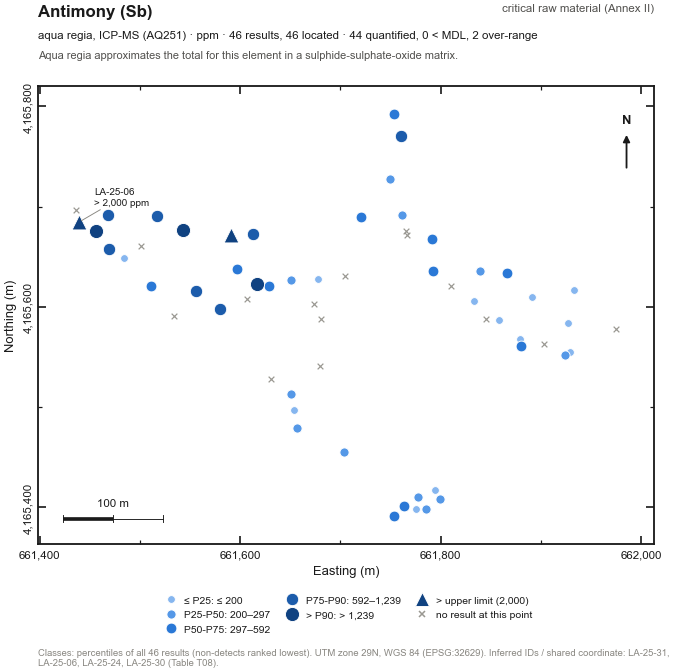

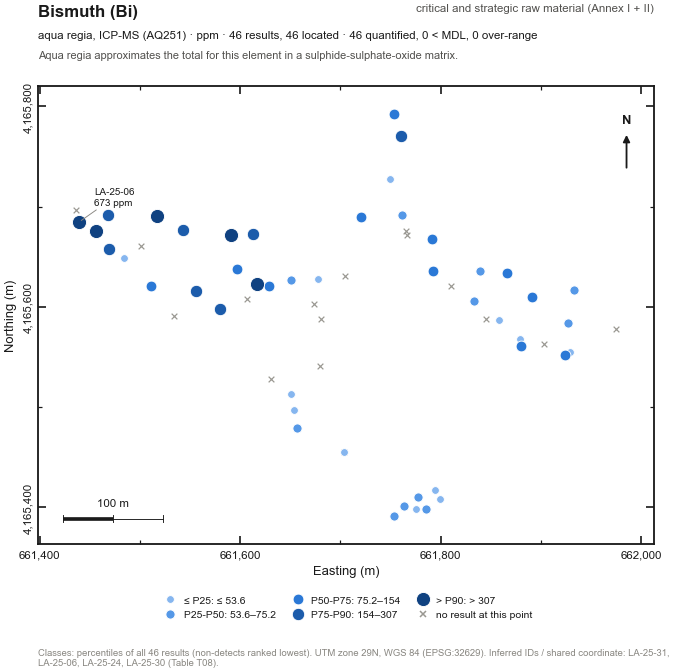

C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1898308880.py:163: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  pdf.savefig(fig)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1898308880.py:163: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  pdf.savefig(fig)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1898308880.py:163: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
 

Saved 37 single-element maps (PDF + SVG) to outputs\ICP_CRM\figures\maps and the atlas Atlas_CRM_maps_ICP.pdf (37 pages).


In [15]:
DISPLAY_UNIT = {"Pd": ("ppb", 1e3), "Pt": ("ppb", 1e3)}          # ppm -> display factor
LF_DISPLAY = {"Ba": ("ppm", "value_ppm", 1.0)}                     # others in wt% oxide as reported
DIGESTION_NOTE = {
    "A": "Aqua regia approximates the total for this element in a sulphide-sulphate-oxide matrix.",
    "B": "Partial digestion: values are the aqua-regia-extractable fraction, not the element content.",
    "C": "Screening only: 2-10 ppb detection limits on a small aliquot; fire assay is the reference method.",
    "F": "Lithium-borate fusion: total content (8 samples).",
}
FLAGGED_IDS = ALL_PTS.index[ALL_PTS["flags"].str.contains("probable|identical", na=False)].tolist()


def map_payload(method, analyte):
    """Values, classes and display settings for one element map."""
    samples = AQ_SAMPLES if method == "AQ251" else LF_SAMPLES
    d = element_data(method, analyte, samples).copy()
    if method == "AQ251":
        el = analyte
        unit, fac = DISPLAY_UNIT.get(el, ("ppm", 1.0))
        d["disp"] = d["value_ppm"] * fac
        d["mdl_disp"] = d["mdl_ppm"] * fac
        cls_key = DIGESTION_CLASS[el]
        title = f"{ELEMENT_NAME[el].capitalize()} ({el})"
    else:
        el = d["element"].iloc[0]
        unit, col, fac = LF_DISPLAY.get(analyte, ("wt%", "value", 1.0))
        d["disp"] = d[col] * fac
        d["mdl_disp"] = (d["mdl_ppm"] if col == "value_ppm" else d["mdl"]) * fac
        cls_key = "F"
        sub = {"SiO2": "SiO₂", "TiO2": "TiO₂", "Al2O3": "Al₂O₃", "P2O5": "P₂O₅"}
        title = f"{ELEMENT_NAME[el].capitalize()} - {sub.get(analyte, analyte)} (fusion)"
    q = d["q"].to_numpy()
    lb = np.where(q == "<", 0.0, d["disp"].to_numpy(float))
    # class limits = the censoring-aware percentiles of section 8 (a limit that falls among the
    # non-detects is set to 0, i.e. '<MDL'), so map legends and statistics tables quote the same numbers
    cs = censored_stats(q, d["disp"].to_numpy(float), float(d["mdl_disp"].iloc[0]))
    br = np.array([0.0 if cs[f"P{p}_flag"] == "<" else cs[f"P{p}"] for p in (25, 50, 75, 90)])
    d["lb"] = lb
    d["cls"] = np.where(q == "<", -1, np.searchsorted(br, lb, side="left"))
    return dict(d=d, el=el, analyte=analyte, method=method, unit=unit, breaks=br, cls_key=cls_key, title=title,
                mdl=float(d["mdl_disp"].iloc[0]))


def class_legend_entries(P, size_scale=1.0):
    """Legend handles: non-empty percentile classes with their limits, then the special symbols."""
    br, unit, mdl = P["breaks"], P["unit"], P["mdl"]
    d = P["d"]
    vmax = float(np.nanmax(d.loc[d["q"] != "<", "disp"])) if (d["q"] != "<").any() else np.nan
    lims = [mdl] + list(br) + [vmax]
    hs = []
    for k in range(5):
        lo, hi = lims[k], lims[k + 1]
        if k == 0:
            if br[0] <= 0:
                continue
            txt = f"≤ {fmt_num(br[0])}"
        elif k == 4:
            if not np.isfinite(vmax) or vmax <= br[3]:
                continue
            txt = (f"> {fmt_num(br[3])}" if br[3] > 0 else f"detected, \u2264 {fmt_num(vmax)}")
        else:
            if hi <= lo or hi <= 0:
                continue
            txt = f"≤ {fmt_num(hi)}" if lo <= 0 else f"{fmt_num(lo)}–{fmt_num(hi)}"
        hs.append(Line2D([], [], ls="", marker="o", ms=np.sqrt(CLASS_SIZES[k] * size_scale),
                         mfc=CLASS_COLOURS[k], mec="white", mew=0.6, label=f"{CLASS_LABELS[k]}: {txt}"))
    if (d["q"] == "<").any():
        hs.append(Line2D([], [], ls="", marker="o", ms=np.sqrt(CLASS_SIZES[0] * size_scale), mfc="white", mec=MUTED,
                         mew=0.9, label=f"< MDL ({fmt_num(mdl)})"))
    if (d["q"] == ">").any():
        ul = float(d.loc[d["q"] == ">", "disp"].iloc[0])
        hs.append(Line2D([], [], ls="", marker="^", ms=np.sqrt(CLASS_SIZES[4] * size_scale), mfc=CLASS_COLOURS[4],
                         mec="white", mew=0.6, label=f"> upper limit ({fmt_num(ul)})"))
    hs.append(Line2D([], [], ls="", marker="x", ms=4.2 * np.sqrt(size_scale), mec=STATUS_COLOURS["grey"], mew=1.0,
                     label="no result at this point"))
    return hs


def draw_element_map(ax, P, size_scale=1.0, label_max=True, label_all=False, furniture=True):
    d = P["d"]
    loc = d[d["located"]]
    bg = ALL_PTS.drop(index=[i for i in loc.index if i in ALL_PTS.index])
    add_basemap(ax)
    ax.scatter(bg["E"], bg["N"], marker="x", s=14 * size_scale, c=STATUS_COLOURS["grey"], linewidths=0.8, zorder=2)
    lt = loc[loc["cls"] == -1]
    ax.scatter(lt["E"], lt["N"], marker="o", s=CLASS_SIZES[0] * size_scale, facecolor="white", edgecolor=MUTED,
               linewidths=0.9, zorder=3)
    for k in range(5):
        g = loc[(loc["cls"] == k) & (loc["q"] == "=")]
        ax.scatter(g["E"], g["N"], marker="o", s=CLASS_SIZES[k] * size_scale, facecolor=CLASS_COLOURS[k],
                   edgecolor="white", linewidths=0.6, zorder=4 + k)
    gt = loc[loc["q"] == ">"]
    ax.scatter(gt["E"], gt["N"], marker="^", s=CLASS_SIZES[4] * size_scale * 1.1, facecolor=CLASS_COLOURS[4],
               edgecolor="white", linewidths=0.6, zorder=10)
    if label_all:
        for sid, r in loc.iterrows():
            v = ("<" + fmt_num(P["mdl"])) if r["q"] == "<" else fmt_num(r["disp"])
            ax.annotate(f"{sid.replace('LA-', '')}: {v}", (r["E"], r["N"]), xytext=(4, 3),
                        textcoords="offset points", fontsize=6, color=INK, zorder=11,
                        bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
    elif label_max and len(loc) and (loc["q"] != "<").any():
        top = loc.loc[loc["lb"].idxmax()]
        v = ("> " if top["q"] == ">" else "") + fmt_num(top["disp"]) + f" {P['unit']}"
        right = (top["E"] - EXTENT[0]) / EXT_W > 0.6
        ax.annotate(f"{top.name}\n{v}", (top["E"], top["N"]), xytext=(-10 if right else 10, 10),
                    textcoords="offset points", ha="right" if right else "left", va="bottom", fontsize=6.5,
                    color=INK, zorder=12, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6),
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
    ax.set_xlim(EXTENT[0], EXTENT[1]); ax.set_ylim(EXTENT[2], EXTENT[3])
    ax.set_aspect("equal", adjustable="box")
    style_frame(ax)
    if furniture:
        small = size_scale < 1
        add_north_arrow(ax, y=0.84 if small else 0.90, size=0.16 if small else 0.085, fontsize=6.5 if small else 8.5)
        add_scale_bar(ax, fontsize=5.8 if small else 7.5, lw=1.8 if small else 2.4)


def single_map_figure(P):
    d = P["d"]
    n, n_loc = len(d), int(d["located"].sum())
    n_lt, n_gt = int((d["q"] == "<").sum()), int((d["q"] == ">").sum())
    fig_w, ax_w = 6.6, 5.6
    ax_h = ax_w * EXT_H / EXT_W
    fig_h = ax_h + 2.05
    fig = plt.figure(figsize=(fig_w, fig_h))
    ax = fig.add_axes([0.105, 1.2 / fig_h, ax_w / fig_w, ax_h / fig_h])
    draw_element_map(ax, P, label_all=(P["method"] == "LF725"))
    utm_axes(ax)
    top = 1 - 0.1 / fig_h
    fig.text(0.105, top, P["title"], fontsize=11, fontweight="bold", va="top")
    tag = ("not on the 2024 lists" if P["el"] == "In" else
           "critical and strategic raw material (Annex I + II)" if P["el"] in STRATEGIC else
           "critical raw material (Annex II)")
    fig.text(0.105 + ax_w / fig_w, top, tag, fontsize=7.5, color=INK_SOFT, va="top", ha="right")
    meth = ("aqua regia, ICP-MS (AQ251)" if P["method"] == "AQ251" else "lithium-borate fusion (LF725)")
    fig.text(0.105, top - 0.24 / fig_h,
             f"{meth} · {P['unit']} · {n} results, {n_loc} located · "
             f"{n - n_lt - n_gt} quantified, {n_lt} < MDL, {n_gt} over-range", fontsize=7.5, va="top")
    fig.text(0.105, top - 0.42 / fig_h, DIGESTION_NOTE[P["cls_key"]], fontsize=7.2, va="top", color=INK_SOFT)
    hs = class_legend_entries(P)
    ax.legend(handles=hs, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=6.8,
              handletextpad=0.3, columnspacing=1.1, borderaxespad=0.2)
    unloc = d.index[~d["located"]].tolist()
    note = (f"Classes: percentiles of all {n} results (non-detects ranked lowest). UTM zone 29N, WGS 84 (EPSG:32629). "
            f"Inferred IDs / shared coordinate: {', '.join(f for f in FLAGGED_IDS if f in d.index) or 'none'} (Table T08).")
    if unloc:
        note += f"\nNot mapped (no coordinates): {len(unloc)} results - {', '.join(unloc)}."
    import textwrap
    note = "\n".join(textwrap.fill(par, 150) for par in note.split("\n"))
    fig.text(0.105, 0.012, note, fontsize=6.2, color=MUTED, va="bottom")
    return fig


MAP_LIST = [("AQ251", e) for e in AQ_CRM + THESIS_EXTRA] + [("LF725", a) for a in LF_CRM]
PAYLOADS = {}
atlas_path = FIG_DIR / "Atlas_CRM_maps_ICP.pdf"
with PdfPages(atlas_path) as pdf:
    for method, an in MAP_LIST:
        P = map_payload(method, an)
        PAYLOADS[(method, an)] = P
        fig = single_map_figure(P)
        stem = f"Map_{'AQ' if method == 'AQ251' else 'LF'}_{an}"
        save_figure(fig, stem, MAP_DIR)
        pdf.savefig(fig)
        if (method, an) in {("AQ251", "Sb"), ("AQ251", "Bi")}:
            plt.show()
        else:
            plt.close(fig)
    info = pdf.infodict()
    info["Title"] = "Lagunazo CRM maps (ICP MS)"
    info["Author"] = "Debbie"
print(f"Saved {len(MAP_LIST)} single-element maps (PDF + SVG) to {MAP_DIR.relative_to(PROJECT_DIR)} and the atlas "
      f"{atlas_path.name} ({len(MAP_LIST)} pages).")

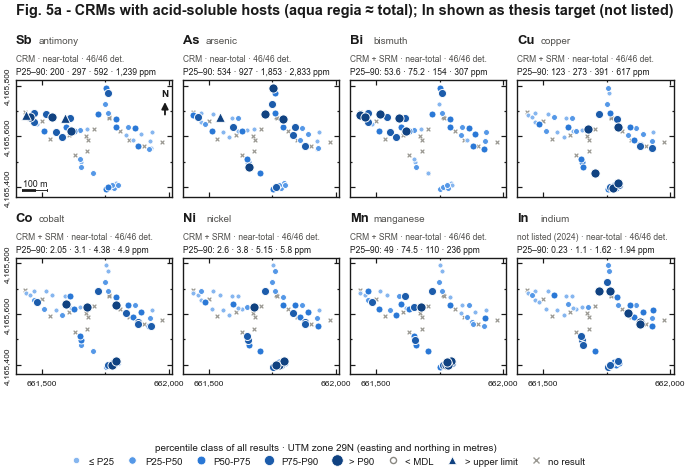

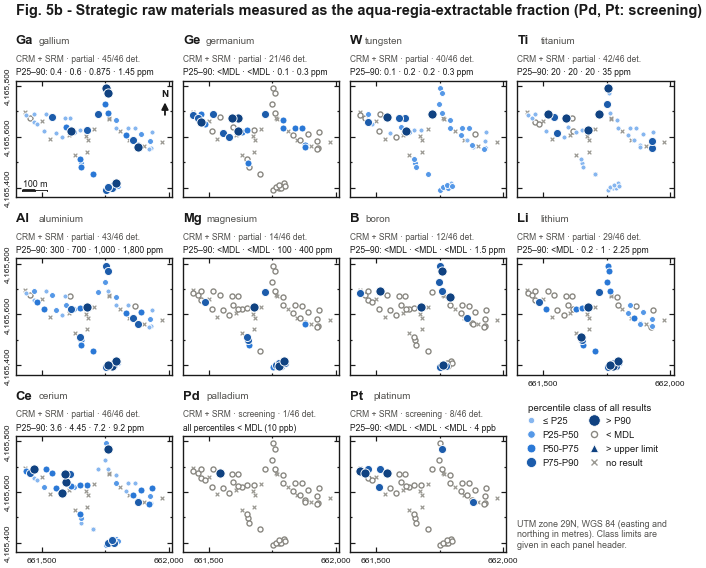

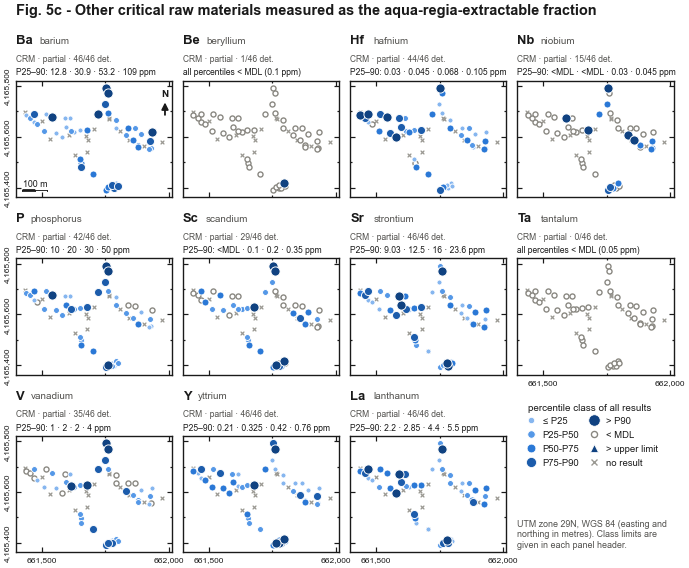

C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.savefig(p)
C:\Users\Debbie Novalina\AppData\Local\Temp\ipykernel_20720\1647005752.py:109: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
  fig.savefig(p)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8323 (\N{SUBSCRIPT THREE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8325 (\N{SUBSCRIPT FIVE}) missing from font(s) Arial.
 

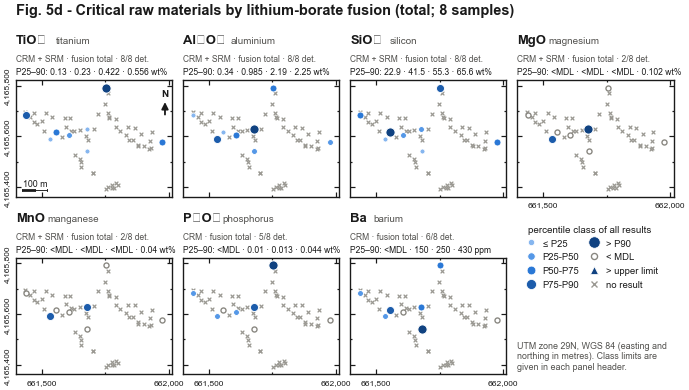

Saved Fig05a-d (37 panels = every CRMA element measured, plus In).


In [16]:
# grouped small multiples (Fig. 5a-d)
SHORT_DIG = {"A": "near-total", "B": "partial", "C": "screening", "F": "fusion total"}


def overview_figure(keys, title, stem, ncols=4, pw=1.42, gap_w=0.1, gap_h=0.12, head=0.44):
    n = len(keys)
    nrows = math.ceil(n / ncols)
    has_free_cell = nrows * ncols > n
    ph = pw * EXT_H / EXT_W
    left, right, top_m = 0.42, 0.08, 0.34
    legend_h = 0.0 if has_free_cell else 0.62
    bottom = 0.38 + legend_h
    W = left + ncols * pw + (ncols - 1) * gap_w + right
    H = top_m + nrows * (head + ph) + (nrows - 1) * gap_h + bottom
    fig = plt.figure(figsize=(W, H))
    fig.text(left / W, 1 - 0.08 / H, title, fontsize=9.5, fontweight="bold", va="top")
    axes = []
    for i, key in enumerate(keys):
        r, c = divmod(i, ncols)
        x0 = left + c * (pw + gap_w)
        y0 = H - top_m - (r + 1) * (head + ph) - r * gap_h
        ax = fig.add_axes([x0 / W, y0 / H, pw / W, ph / H])
        P = PAYLOADS[key]
        draw_element_map(ax, P, size_scale=0.42, label_max=False, furniture=(i == 0))
        utm_axes(ax, label=False, nbins=3, labelsize=5.5)     # full easting/northing in metres, as on the single maps
        ax.tick_params(labelsize=5.5, length=3, width=0.8)
        ax.tick_params(which="minor", length=1.6)
        last_row_here = (r == nrows - 1) or (i + ncols >= n)
        if not last_row_here:
            ax.tick_params(labelbottom=False)
        if c != 0:
            ax.tick_params(labelleft=False)
        for t in ax.get_yticklabels():
            t.set_rotation(90); t.set_va("center")
        for s_ in ax.spines.values():
            s_.set_linewidth(0.9)
        d = P["d"]
        nq = int((d["q"] != "<").sum())
        lab = (P["analyte"].translate(str.maketrans("0123456789", "₀₁₂₃₄₅₆₇₈₉"))
               if P["method"] == "LF725" else P["el"])
        name = ELEMENT_NAME.get(P["el"], P["el"])
        yt = (y0 + ph + head) / H
        fig.text(x0 / W, yt - 0.02 / H, f"{lab}", fontsize=8.5, fontweight="bold", va="top")
        fig.text((x0 + 0.06 + 0.075 * len(lab)) / W, yt - 0.035 / H, name, fontsize=6.5, va="top", color=INK_SOFT)
        fig.text(x0 / W, yt - 0.2 / H, f"{crma_status(P['el'])} · {SHORT_DIG[P['cls_key']]} · {nq}/{len(d)} det.",
                 fontsize=5.6, va="top", color=INK_SOFT)
        br = [("<MDL" if b <= 0 else fmt_num(b)) for b in P["breaks"]]
        brk_txt = (f"P25–90: {' · '.join(br)} {P['unit']}" if any(b > 0 for b in P["breaks"])
                   else f"all percentiles < MDL ({fmt_num(P['mdl'])} {P['unit']})")
        fig.text(x0 / W, yt - 0.32 / H, brk_txt, fontsize=5.6, va="top")
        axes.append(ax)
    # shared legend (percentile classes and special symbols)
    hs = [Line2D([], [], ls="", marker="o", ms=np.sqrt(CLASS_SIZES[k] * 0.42) * 1.25, mfc=CLASS_COLOURS[k],
                 mec="white", mew=0.5, label=CLASS_LABELS[k]) for k in range(5)]
    hs += [Line2D([], [], ls="", marker="o", ms=4.0, mfc="white", mec=MUTED, mew=0.9, label="< MDL"),
           Line2D([], [], ls="", marker="^", ms=5.0, mfc=CLASS_COLOURS[4], mec="white", mew=0.5, label="> upper limit"),
           Line2D([], [], ls="", marker="x", ms=3.6, mec=STATUS_COLOURS["grey"], mew=0.9, label="no result")]
    if has_free_cell:
        r, c = divmod(n, ncols)
        x0 = left + c * (pw + gap_w)
        y0 = H - top_m - (r + 1) * (head + ph) - r * gap_h
        lax = fig.add_axes([x0 / W, y0 / H, (W - x0 - right) / W, (ph + head) / H])
        lax.axis("off")
        lax.legend(handles=hs, loc="upper left", bbox_to_anchor=(0.0, 0.93), ncol=2, fontsize=6.2,
                   title="percentile class of all results", title_fontsize=6.4, handletextpad=0.25,
                   columnspacing=0.6, frameon=False, borderaxespad=0.0)
        lax.text(0.0, 0.02, "UTM zone 29N, WGS 84 (easting and\nnorthing in metres). Class limits are\n"
                 "given in each panel header.", transform=lax.transAxes, fontsize=5.8, color=INK_SOFT,
                 va="bottom")
    else:
        fig.legend(handles=hs, loc="lower center", bbox_to_anchor=(0.5, 0.02), ncol=8, fontsize=6.3,
                   handletextpad=0.3, columnspacing=0.9, frameon=False,
                   title="percentile class of all results · UTM zone 29N (easting and northing in metres)",
                   title_fontsize=6.5)
    save_figure(fig, stem)
    return fig


GROUPS = [
    ([("AQ251", e) for e in ["Sb", "As", "Bi", "Cu", "Co", "Ni", "Mn", "In"]],
     "Fig. 5a - CRMs with acid-soluble hosts (aqua regia ≈ total); In shown as thesis target (not listed)",
     "Fig05a_maps_nearTotal_CRMs"),
    ([("AQ251", e) for e in ["Ga", "Ge", "W", "Ti", "Al", "Mg", "B", "Li", "Ce", "Pd", "Pt"]],
     "Fig. 5b - Strategic raw materials measured as the aqua-regia-extractable fraction (Pd, Pt: screening)",
     "Fig05b_maps_partial_strategic"),
    ([("AQ251", e) for e in ["Ba", "Be", "Hf", "Nb", "P", "Sc", "Sr", "Ta", "V", "Y", "La"]],
     "Fig. 5c - Other critical raw materials measured as the aqua-regia-extractable fraction",
     "Fig05c_maps_partial_critical"),
    ([("LF725", a) for a in LF_CRM],
     "Fig. 5d - Critical raw materials by lithium-borate fusion (total; 8 samples)",
     "Fig05d_maps_fusion_totals"),
]
for keys, title, stem in GROUPS:
    fig = overview_figure(keys, title, stem)
    plt.show()
covered = {k for g in GROUPS for k in g[0]}
assert covered == set(PAYLOADS), "every single-element map appears in one overview figure"
print(f"Saved Fig05a-d ({sum(len(g[0]) for g in GROUPS)} panels = every CRMA element measured, plus In).")

## 10 · Optional: paired pXRF-ICP comparison

This section runs only when `XRF_Lagunazo_complete_r2.csv` (the pXRF readings used by `Final_XRF_samples_mapping_r3.ipynb`) is in `data/`. Readings are combined per sample by the median, exactly as in Part B of the pXRF notebook, and joined to the ICP results on the normalised sample ID. The overlap is expected to be the 2024 series (`LA-24-nn`), the only samples that went both to the handheld analyser and to the laboratory.

Two things must be kept apart when reading the result. For class A elements (Sb, Bi, As, Cu, Co, Ni, Mn) the ratio pXRF/ICP measures the **field method against the laboratory**, and a systematic departure from 1 is a calibration bias that carries straight into any grade or tonnage built on the pXRF data. For class B elements (Ti, Nb, Y, Zr, Sr, W, V) aqua regia is partial, so pXRF ≫ ICP is expected and says nothing about pXRF accuracy. The pXRF readings were taken on unprepared material and the laboratory analysed a pulverised split, so part of any scatter is sample heterogeneity, not analytical error.

pXRF samples: 87; overlap with ICP AQ251 samples: 10 (LA-24-19, LA-24-20, LA-24-21, LA-24-24, LA-24-25, LA-24-26, LA-24-27, LA-24-28, LA-24-30, LA-24-31)

PAIRED pXRF / ICP (median of sample ratios; ICP over-range and non-detects excluded)
        digestion  n_pairs  median_ratio_pXRF_over_ICP  ratio_P25  ratio_P75  spearman_rho
element                                                                                   
As              A        9                        0.98       0.63       1.13          0.57
Bi              A       10                        1.25       0.64       1.41          0.78
Cu              A       10                        0.65       0.37       1.30          0.71
Fe              A       10                        1.16       0.53       1.80          0.50
Mn              A        3                        3.32       2.04       3.37           NaN
Mo              A        9                        1.73       0.87       2.94          0.30
Nb              B        5      

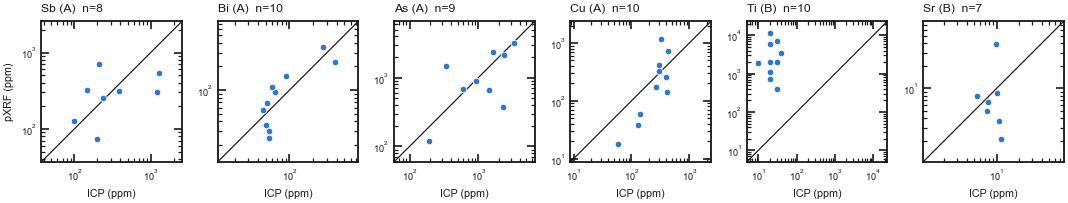

In [17]:
PXRF_PAIRS = None
if PXRF_DATA_FILE is None:
    print("XRF_Lagunazo_complete_r2.csv not found in data/ - paired comparison skipped.")
else:
    try:
        xr = pd.read_csv(PXRF_DATA_FILE)
        xr.columns = [str(c).strip() for c in xr.columns]
        xr["ID_final"] = [canonical_id(str(v).replace("_", "-"))[0] for v in xr["Sample"]]
        comp = ["Sb", "Bi", "As", "Cu", "Co", "Ni", "Mn", "Zn", "Fe", "Pb", "Ti", "V", "W", "Sr", "Nb", "Y", "Zr",
                "Sn", "Mo"]
        comp = [e for e in comp if e in xr.columns]

        def _num(s):
            s = s.astype("string").str.strip()
            bad = s.str.startswith("<", na=False) | s.str.contains("LOD", case=False, na=False)
            return pd.to_numeric(s.mask(bad, pd.NA), errors="coerce").astype("float64")

        xs_ = pd.DataFrame({e: _num(xr[e]) for e in comp})
        xs_["ID_final"] = xr["ID_final"].to_numpy()
        PX = xs_.groupby("ID_final")[comp].median()
        overlap = sorted(set(PX.index) & set(AQ_SAMPLES))
        print(f"pXRF samples: {len(PX)}; overlap with ICP AQ251 samples: {len(overlap)} ({', '.join(overlap)})")
        rows = []
        for el in comp:
            d = element_data("AQ251", el, overlap)
            for sid in overlap:
                if sid not in d.index:
                    continue
                r = d.loc[sid]
                rows.append(dict(sample_id=sid, element=el, pXRF_ppm=PX.loc[sid, el], ICP_ppm=r["value_ppm"],
                                 ICP_q=r["q"], digestion=DIGESTION_CLASS.get(el, "A" if el in
                                                                          ("Zn", "Fe", "Pb", "Mo") else "B")))
        PXRF_PAIRS = pd.DataFrame(rows)
        PXRF_PAIRS[["pXRF_ppm", "ICP_ppm"]] = PXRF_PAIRS[["pXRF_ppm", "ICP_ppm"]].astype("float64")
        ok = PXRF_PAIRS[(PXRF_PAIRS["ICP_q"] == "=") & PXRF_PAIRS["pXRF_ppm"].gt(0)]
        summ = []
        for el, g in ok.groupby("element"):
            lr = np.log10(g["pXRF_ppm"] / g["ICP_ppm"])
            rho = sps.spearmanr(g["pXRF_ppm"], g["ICP_ppm"])[0] if len(g) >= 5 else np.nan
            summ.append(dict(element=el, digestion=g["digestion"].iloc[0], n_pairs=len(g),
                             median_ratio_pXRF_over_ICP=10 ** lr.median(),
                             ratio_P25=10 ** lr.quantile(0.25), ratio_P75=10 ** lr.quantile(0.75), spearman_rho=rho))
        PXRF_SUMMARY = pd.DataFrame(summ).set_index("element")
        print("\nPAIRED pXRF / ICP (median of sample ratios; ICP over-range and non-detects excluded)")
        print(PXRF_SUMMARY.round(2).to_string())
        print("\n  Class A rows test the pXRF calibration; class B rows reflect partial aqua regia digestion.")
        els = [e for e in ["Sb", "Bi", "As", "Cu", "Ti", "Sr"] if e in PXRF_SUMMARY.index]
        if els:
            fig, axs = plt.subplots(1, len(els), figsize=(1.55 * len(els) + 0.6, 2.2), squeeze=False)
            for ax, el in zip(axs[0], els):
                g = ok[ok["element"] == el]
                ax.scatter(g["ICP_ppm"], g["pXRF_ppm"], s=18, facecolor=STATUS_COLOURS["blue"], edgecolor="white",
                           linewidth=0.5, zorder=3)
                lo = min(g["ICP_ppm"].min(), g["pXRF_ppm"].min()) / 2
                hi = max(g["ICP_ppm"].max(), g["pXRF_ppm"].max()) * 2
                ax.plot([lo, hi], [lo, hi], color=INK, lw=0.8)
                ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
                ax.set_aspect("equal")
                ax.set_title(f"{el} ({DIGESTION_CLASS.get(el, '-')})  n={len(g)}", fontsize=8, loc="left")
                ax.set_xlabel("ICP (ppm)", fontsize=7); ax.tick_params(labelsize=6)
                style_frame(ax, xminor=None, yminor=None)
            axs[0][0].set_ylabel("pXRF (ppm)", fontsize=7)
            fig.tight_layout()
            save_figure(fig, "Fig06_pXRF_vs_ICP")
            plt.show()
        PXRF_PAIRS.to_csv(TAB_DIR / "T14_pXRF_ICP_pairs.csv", index=False, encoding="utf-8-sig")
        PXRF_SUMMARY.to_csv(TAB_DIR / "T15_pXRF_ICP_summary.csv", encoding="utf-8-sig")
    except Exception as exc:
        print(f"Paired comparison skipped: {type(exc).__name__}: {exc}")
        PXRF_PAIRS = None

## 11 · GIS export, findings and draft text for the thesis

The located samples are exported with every CRM value (lower-bound numeric value in ppm plus the laboratory string, so a `<` or `>` is never lost) as a CSV in UTM zone 29N and as a GeoJSON in WGS 84 longitude/latitude (the GeoJSON standard, RFC 7946), ready for QGIS or for the geostatistics notebooks. The findings below are assembled from the objects computed above, so they update with the data.

In [18]:
# GIS export
to_ll = Transformer.from_crs(CRS_PROJECTED, CRS_GEOGRAPHIC, always_xy=True)
wide_raw = A[A["method"] == "AQ251"].pivot(index="sample_id", columns="analyte", values="raw")
wide_ppm = A[A["method"] == "AQ251"].pivot(index="sample_id", columns="analyte", values="value_ppm")
wide_q = A[A["method"] == "AQ251"].pivot(index="sample_id", columns="analyte", values="q")
GIS = SAMPLES[SAMPLES["located"]][["E", "N", "AQ251", "LF725", "received_kg", "waste_type", "source", "flags"]].copy()
GIS["lon"], GIS["lat"] = to_ll.transform(GIS["E"].to_numpy(), GIS["N"].to_numpy())
for el in AQ_CRM + THESIS_EXTRA:
    v = wide_ppm[el].where(wide_q[el] != "<", 0.0)          # non-detect -> 0 in the numeric column
    GIS[f"{el}_ppm"] = v.reindex(GIS.index)
    GIS[f"{el}_lab"] = wide_raw[el].reindex(GIS.index)     # laboratory string, e.g. '<0.1', '>2000.00'
for an in LF_CRM:
    g = A[(A["method"] == "LF725") & (A["analyte"] == an)].set_index("sample_id")
    GIS[f"{an}_LF725_lab"] = g["raw"].reindex(GIS.index)
GIS.index.name = "sample_id"
GIS.to_csv(TAB_DIR / "T16_located_samples_CRM_values_UTM29N.csv", encoding="utf-8-sig")
features = []
for sid, r in GIS.iterrows():
    props = {"sample_id": sid}
    for k, v in r.items():
        if k in ("lon", "lat"):
            continue
        props[k] = (None if (isinstance(v, float) and not np.isfinite(v)) else
                    (float(v) if isinstance(v, (np.floating, float)) else (None if pd.isna(v) else str(v))))
    features.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(r["lon"], 7),
                                                                                     round(r["lat"], 7)]},
                     "properties": props})
with open(OUT_DIR / "Lagunazo_ICP_samples_WGS84.geojson", "w", encoding="utf-8") as fh:
    json.dump({"type": "FeatureCollection", "features": features}, fh, ensure_ascii=False, indent=1)
print(f"Saved T16_located_samples_CRM_values_UTM29N.csv and Lagunazo_ICP_samples_WGS84.geojson ({len(GIS)} points)")

Saved T16_located_samples_CRM_values_UTM29N.csv and Lagunazo_ICP_samples_WGS84.geojson (55 points)


In [19]:
# findings
S = CRM_STATS


def q_(el, col):
    return fmt_stat(S.loc[el, col], S.loc[el, f"{col}_flag"] if f"{col}_flag" in S.columns else "")


enriched = S[(S["digestion"].str.startswith("A")) & (S["median_x_UCC"] > 5) & (S.index != "In")].sort_values(
    "median_x_UCC", ascending=False)
n_irreg = int((~LOC["ID_note"].isin(["ok", "LG->LA prefix"])).sum())
depleted = S[(S["digestion"].str.startswith("A")) & (S["median_x_UCC"] < 1)]
not_det = S[S["detection_pct"] < 20]
lf_ti = LF_STATS.loc["TiO2 (LF725)"]
rho = lambda a, b: RHO.loc[a, b] if (a in RHO.index and b in RHO.columns) else np.nan
_locd = SAMPLES[SAMPLES["located"] & (SAMPLES["AQ251"] == "reported")]
_W = (A[A["method"] == "AQ251"].pivot(index="sample_id", columns="analyte", values="value_ppm").loc[_locd.index])


def top_txt(group, k=6):
    r = _W[group].rank(pct=True).mean(axis=1).sort_values(ascending=False).head(k)
    e, n_ = _locd.loc[r.index, "E"].mean(), _locd.loc[r.index, "N"].mean()
    return f"{', '.join(r.index)} (mean position E {e:,.0f}, N {n_:,.0f})"

print("=" * 110)
print("FINDINGS - LAGUNAZO ICP DATA AND CRITICAL RAW MATERIALS (EU CRMA 2024)")
print("=" * 110)
print(f"""
DATASET
  {n_rows} samples in this export of job {HDR.get('Job Number')} ({HDR.get('Number of Samples')} samples in the whole job):
  {n_aq} with aqua regia ICP-MS (AQ251), {n_lf} with lithium-borate fusion (LF725; {n_both} by both), {n_is} returned
  as insufficient sample. {int(SAMPLES.loc[AQ_SAMPLES, 'located'].sum())} of the {n_aq} AQ251 samples are located;
  {len(unlocated[unlocated['AQ251'] == 'reported'])} LA-24 samples have no coordinates in the workbook.

LABORATORY QC""")
for r in QC_VERDICT.itertuples():
    print(f"  - {r.aspect}: {r.consequence}.")
print(f"""
LOCATIONS
  {len(LOC)} field points, {'all' if len(outside) == 0 else f'{len(LOC) - len(outside)}'} inside the pXRF survey frame. {n_irreg} IDs have format irregularities
  (letter case, zero padding, prefix, year) and one ID is recorded twice; {len(LOCATION_ID_CORRECTIONS)} corrections are inferred
  (rows {', '.join(str(k) for k in LOCATION_ID_CORRECTIONS)}), after which the 2025 numbers 01-{nums.max():02d} are {'complete and unique' if not missing_nums and not repeated_nums else 'still incomplete'}.
  {' and '.join(dup_xy['ID_final'])} share one coordinate, so their individual locations are uncertain [CONFIRM from the GNSS log].

CRITICAL RAW MATERIALS (AQ251, n = {n_aq})""")
for el, r in enriched.iterrows():
    print(f"  {el:<2} median {q_(el, 'P50'):>6} ppm, P90 {q_(el, 'P90'):>6}, max {q_(el, 'max'):>8} ppm "
          f"-> {r['median_x_UCC']:,.0f} x upper continental crust at the median")
_low = ", ".join(e + " " + q_(e, "P50") for e in ["Co", "Ni", "Mn"])
_low_x = ", ".join(f"{v:.2f}" for v in depleted.loc[["Co", "Ni", "Mn"], "median_x_UCC"])
print(f"  Co, Ni and Mn are below crustal background (medians {_low} ppm; {_low_x} x UCC).")
print(f"  Ga (median {q_('Ga', 'P50')} ppm), Ge (median {q_('Ge', 'P50')} ppm, {S.loc['Ge', 'detection_pct']:.0f} % detected) and W "
      f"(max {q_('W', 'max')} ppm) are at or near their detection limits.")
print(f"  In (thesis target, not on the 2024 lists): median {q_('In', 'P50')} ppm, max {q_('In', 'max')} ppm - "
      f"about {S.loc['In', 'median_x_UCC']:.0f} x crust, at the ppm level.")
print(f"  Not detected or near-absent: {', '.join(f'{e} ({r.detection_pct:.0f} %)' for e, r in not_det.iterrows())}.")
print(f"  Ti by fusion (total): {fmt_num(lf_ti['min_quantified'])}-{fmt_num(lf_ti['max'])} ppm, median {fmt_num(lf_ti['P50'])} ppm "
      f"({lf_ti['median_x_UCC']:.2f} x UCC) - crustal background or below, consistent with treating Ti as a background")
print(f"  inventory item; aqua regia recovers only {ti_rng['min']:.0f}-{ti_rng['max']:.0f} % of it.")
print(f"""
ASSOCIATIONS
  Sb-Bi rho = {rho('Sb', 'Bi'):+.2f}; both follow Au (rho {rho('Sb', 'Au'):+.2f}, {rho('Bi', 'Au'):+.2f}), Ag and Hg. Cu, Co, Ni, Zn, In and Fe form a
  second group (Cu-Co {rho('Cu', 'Co'):+.2f}, Cu-Ni {rho('Cu', 'Ni'):+.2f}, Cu-Fe {rho('Cu', 'Fe'):+.2f}) that is inversely related to Sb-Bi
  (Bi-Cu {rho('Bi', 'Cu'):+.2f}, Sb-Cu {rho('Sb', 'Cu'):+.2f}). As follows neither group (As-Sb {rho('As', 'Sb'):+.2f}).
  Highest-ranked located samples (mean percentile rank across the group, Fig. 5a):
    Sb-Bi          : {top_txt(['Sb', 'Bi'])}
    Cu-Co-Ni-Mn-In : {top_txt(['Cu', 'Co', 'Ni', 'Mn', 'In'])}

WHAT THIS MEANS FOR THE THESIS (framing, not conclusions)
  - The laboratory data confirm Sb, Bi, As and Cu as the enriched CRMs; the Sb-Bi pairing that underpins the co-kriging
    model is stronger in the ICP data (rho {rho('Sb', 'Bi'):.2f}) than reported for the pXRF data ({PXRF_SB_BI_RHO:.2f}).
  - Cu does not travel with Sb-Bi: a 'polymetallic Bi-Sb-Cu suite' is two material signatures side by side rather than
    one assemblage, which matters for domaining and for any recovery flowsheet [CONFIRM against field descriptions].
  - Before the ICP grades are compared with the pXRF-based grades or the Exploration Target, run §10 with the pXRF file:
    the ICP medians (Sb {q_('Sb', 'P50')}, Bi {q_('Bi', 'P50')}, Cu {q_('Cu', 'P50')} ppm) come from a different sample set, so no
    bias can be inferred from medians alone.
  - Class B maps must be captioned as aqua-regia-extractable concentrations, and Ta, Be, Pd and Pt described as not detected
    at the stated limits, not as absent.""")

FINDINGS - LAGUNAZO ICP DATA AND CRITICAL RAW MATERIALS (EU CRMA 2024)

DATASET
  55 samples in this export of job PLKRK2600014 (146 samples in the whole job):
  46 with aqua regia ICP-MS (AQ251), 8 with lithium-borate fusion (LF725; 4 by both), 5 returned
  as insufficient sample. 46 of the 46 AQ251 samples are located;
  0 LA-24 samples have no coordinates in the workbook.

LABORATORY QC
  - Contamination (method blanks): no effect on any result.
  - Carry-over in preparation: no sign of carry-over.
  - Accuracy, aqua regia (OREAS 262): accurate at the concentrations of the standard.
  - Accuracy at sample grades: NOT demonstrated for Sb, Bi and As at sample grades - no grade-bracketing standard.
  - Accuracy, fusion (SY-4, OREAS 73b, OREAS 133b): accurate for the major oxides; minor oxides limited by the 0.01 % MDL.
  - Analytical precision: good, but one pair is a check, not a precision estimate.
  - Sampling precision: not quantified - state this limitation in the thesis.
  - Comp

In [20]:
# paste-ready methods and QA/QC paragraph
_fe = O262_SUM.set_index("analyte").loc["Fe"]
PARA_RAW = f"""
Laboratory analysis. The Lagunazo samples (n = {n_rows}) were submitted to Bureau Veritas Minerals (job
{HDR.get('Job Number')}; received {HDR.get('Received')}, reported {HDR.get('File Created')}) [CONFIRM laboratory name and accreditation].
Aqua regia digestion with an ICP-MS finish (package AQ251, 53 elements) was applied to {n_aq} samples and lithium-borate
fusion (package LF725: major oxides, Ba, Cu, Pb and Zn) to {n_lf}, {n_both} of them by both methods; a further {n_is} samples
were returned as insufficient for analysis. Aqua regia dissolves sulphide, sulphate and oxyhydroxide hosts but not
silicate and resistate minerals, so results for lithophile elements are reported as aqua-regia-extractable
concentrations: on the samples analysed by both methods, aqua regia recovered {ti_rng['min']:.0f}–{ti_rng['max']:.0f} % of the Ti and
{al_rng['min']:.0f}–{al_rng['max']:.0f} % of the Al measured by fusion, against {XM_SUM.loc['Fe', 'min']:.0f}–{XM_SUM.loc['Fe', 'max']:.0f} % of the Fe.

Quality control. Data quality was assessed from the laboratory's internal controls, as no client-inserted blanks,
duplicates or reference materials were submitted [CONFIRM]; sampling precision is therefore not quantified. The five
method blanks were below the detection limit for {int((BLANKS['n_above_MDL'] == 0).sum())} of {len(BLANKS)} analytes, and the remaining detections
were below 1 % of the lowest sample concentration. In six insertions of the certified reference material OREAS 262,
{n_pass_crm} of the {n_cert_crm} certified critical-raw-material analytes fell within two standard deviations of the
certified value in every run, while iron was biased low by about {abs(_fe['mean_bias_pct']):.0f} %. Because OREAS 262 and the
laboratory standard BVGEO01 contain only single-digit to low tens of ppm Sb and Bi, accuracy at the Sb, Bi and As
concentrations of the samples is not demonstrated by these data. The single pulp repeat of a Lagunazo sample
(LA-25-03) agreed within {_la03['RPD_pct'].max():.1f} % for every critical-raw-material analyte above ten times its detection limit.
Antimony exceeded the upper reporting limit of {fmt_num(float(CENSORING.loc['Sb', 'upper_limit']))} ppm in
{int(CENSORING.loc['Sb', 'over_range'])} samples and arsenic that of {fmt_num(float(CENSORING.loc['As', 'upper_limit']))} ppm in
{int(CENSORING.loc['As', 'over_range'])}; these results are treated as lower bounds.
"""
import textwrap
PARA = "\n\n".join(" ".join(p.split()) for p in PARA_RAW.strip().split("\n\n"))   # reflow: one line per paragraph
print("\n\n".join(textwrap.fill(p, 115) for p in PARA.split("\n\n")))
(OUT_DIR / "draft_methods_QAQC_paragraph.txt").write_text(PARA + "\n", encoding="utf-8")

CONFIRM = [
    "Laboratory name, location of analysis (Krakow receipt / Vancouver batches) and accreditation - not printed in the export.",
    "AQ251 aliquot mass and digestion conditions; LF725 finish (XRF or ICP) - from the Bureau Veritas method sheet.",
    "Certified values transcribed for OREAS 262, OREAS 73b, OREAS 133b and SY-4 against the certificate revisions in hand.",
    "That field IDs 'LG-25-nn' and laboratory IDs 'LA-25-nn' are the same samples.",
    "The three inferred ID corrections (rows 13, 23, 29 of the Locations sheet) against the field notebook / GNSS waypoints.",
    "The true coordinate of LA-25-30 (identical to LA-25-32 in the sheet).",
    "Waste type (tailings, slag, roasted pyrite ash, other) of every LA-25 sample - fill WASTE_TYPE_OVERRIDES.",
    "GNSS datum (WGS 84 assumed) and receiver accuracy.",
    "Whether an ore-grade re-assay was requested for Sb (2 samples), As (1) and Pb (39 without fusion Pb).",
]
print("[CONFIRM] ITEMS")
for i, c in enumerate(CONFIRM, 1):
    print(f"  {i}. {c}")

print("\nOUTPUTS")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and p.parent != MAP_DIR:
        print(f"  {p.relative_to(OUT_DIR)}")
print(f"  figures/maps/: {len(list(MAP_DIR.glob('*.pdf')))} PDF + {len(list(MAP_DIR.glob('*.svg')))} SVG single-element maps")

Laboratory analysis. The Lagunazo samples (n = 55) were submitted to Bureau Veritas Minerals (job PLKRK2600014;
received 15-Jan-2026, reported 29-Apr-2026) [CONFIRM laboratory name and accreditation]. Aqua regia digestion with
an ICP-MS finish (package AQ251, 53 elements) was applied to 46 samples and lithium-borate fusion (package LF725:
major oxides, Ba, Cu, Pb and Zn) to 8, 4 of them by both methods; a further 5 samples were returned as insufficient
for analysis. Aqua regia dissolves sulphide, sulphate and oxyhydroxide hosts but not silicate and resistate
minerals, so results for lithophile elements are reported as aqua-regia-extractable concentrations: on the samples
analysed by both methods, aqua regia recovered 1–30 % of the Ti and 16–32 % of the Al measured by fusion, against
85–96 % of the Fe.

Quality control. Data quality was assessed from the laboratory's internal controls, as no client-inserted blanks,
duplicates or reference materials were submitted [CONFIRM]; sampling pre